# Préparation du dataset : l'éducation au Maroc (textes arabes)

**Projet de Deep Learning — Traitement automatique du langage naturel (NLP)**
Master MBD — Faculté des Sciences et Techniques de Tanger

## Objectif

Ce notebook constitue la première étape de la partie 1 du TP (tâche de classification). On y collecte des textes arabes sur un même sujet, l'éducation au Maroc, à partir de plusieurs sources, puis on attribue à chaque texte un score de pertinence compris entre 0 et 10. Le résultat est un fichier `dataset_education_maroc.csv` au format demandé (`Text`, `Score`).

## Plan

1. Configuration
2. Source 1 : Wikipédia arabe
3. Source 2 : revue RMPRS (exploration et sélection)
4. Article RMPRS 484 : texte complet par OCR
5. Articles RMPRS complémentaires (résumés)
6. Textes peu pertinents (Wikipédia)
7. Construction du dataset final
8. Contrôle de qualité et sauvegarde
9. Bilan et limites

## 1. Configuration

On installe les bibliothèques de collecte (`requests`, `BeautifulSoup`, `pandas`), puis on fixe les paramètres généraux : session HTTP réutilisable avec un `User-Agent` explicite, adresses des deux sources (API de Wikipédia arabe et archives de la revue RMPRS) et nom de la revue.

In [ ]:
!pip -q install requests beautifulsoup4 pandas

In [ ]:
# Bibliothèques pour les requêtes HTTP
import requests
import time
import re

# Bibliothèque pour analyser les pages HTML
from bs4 import BeautifulSoup
from urllib.parse import urljoin

# Bibliothèque pour organiser les données
import pandas as pd

# Configuration générale des requêtes HTTP
HEADERS = {
    "User-Agent": "EducationMarocNLP/1.0 (student research project)"
}

# Création d'une session HTTP réutilisable
session = requests.Session()
session.headers.update(HEADERS)

# Adresse de l'API Wikipédia en arabe
WIKIPEDIA_API = "https://ar.wikipedia.org/w/api.php"

# Adresse des archives de la revue marocaine
RMPRS_ARCHIVE = "https://rmprs.com/index.php/rmprs/ar/issue/archive"

# Nom de la revue, utilisé dans la colonne « source » du dataset
RMPRS_SOURCE = "Revue Marocaine de Publication des Recherches Scientifiques (RMPRS)"

print("Bibliothèques importées avec succès.")
print("Configuration générale terminée.")

Bibliothèques importées avec succès.
Configuration générale terminée.


### 1.1 Sujet et mots-clés

Le sujet retenu est l'éducation au Maroc. Douze expressions arabes couvrent ses principaux aspects (enseignement scolaire et supérieur, réforme, décrochage scolaire, enseignement numérique, enseignants, étudiants, baccalauréat, formation professionnelle) et servent de requêtes de recherche.

In [ ]:
# Sujet principal du corpus
TOPIC = "L'éducation au Maroc"

# Mots-clés arabes pour rechercher des articles pertinents
KEYWORDS = [
    "التعليم في المغرب",
    "التعليم المدرسي في المغرب",
    "المدارس المغربية",
    "التعليم العالي في المغرب",
    "الجامعات المغربية",
    "إصلاح التعليم في المغرب",
    "الهدر المدرسي في المغرب",
    "التعليم الرقمي في المغرب",
    "الأساتذة في المغرب",
    "الطلاب في المغرب",
    "امتحانات البكالوريا في المغرب",
    "التكوين المهني في المغرب"
]

# Langue souhaitée pour le corpus
TARGET_LANGUAGE = "ar"

# Nombre initial de textes souhaités
TARGET_SIZE = 100

print("Sujet :", TOPIC)
print("Nombre de mots-clés :", len(KEYWORDS))
print("Langue cible :", TARGET_LANGUAGE)
print("Objectif initial :", TARGET_SIZE, "textes")

Sujet : L'éducation au Maroc
Nombre de mots-clés : 12
Langue cible : ar
Objectif initial : 100 textes


### 1.2 Structure du dataset

Chaque article est enregistré avec les mêmes colonnes, quelle que soit sa source : identifiant, titre, texte, source, URL, date, langue, licence et score. Les articles de chaque source sont ajoutés à ce DataFrame unique.

In [ ]:
# Définition des colonnes du dataset
DATASET_COLUMNS = [
    "id",
    "title",
    "text",
    "source",
    "url",
    "date",
    "language",
    "license",
    "score"
]

# Création d'un DataFrame vide avec cette structure
df_dataset = pd.DataFrame(columns=DATASET_COLUMNS)

# Affichage de la structure
print("Structure du dataset :")
print(df_dataset.columns.tolist())

print("\nNombre initial de textes :", len(df_dataset))

# Affichage du tableau vide
display(df_dataset.head())

Structure du dataset :
['id', 'title', 'text', 'source', 'url', 'date', 'language', 'license', 'score']

Nombre initial de textes : 0


,id,title,text,source,url,date,language,license,score


## 2. Source 1 : Wikipédia arabe

### 2.1 Recherche d'articles

On interroge l'API de Wikipédia arabe avec chaque mot-clé (20 résultats par requête). L'API peut renvoyer une erreur 429 (*Too Many Requests*) lorsque les requêtes sont trop rapprochées : c'est le cas pour les deux dernières recherches. Elles sont relancées par une fonction qui attend de plus en plus longtemps entre deux tentatives.

In [ ]:
# Fonction pour rechercher des articles à partir d'un mot-clé
def search_wikipedia(keyword, limit=20):

    params = {
        "action": "query",
        "format": "json",
        "list": "search",
        "srsearch": keyword,
        "srlimit": limit
    }

    response = session.get(
        WIKIPEDIA_API,
        params=params,
        timeout=30
    )

    response.raise_for_status()

    data = response.json()

    return data["query"]["search"]


# Recherche des articles pour chaque mot-clé
wikipedia_results = []

for keyword in KEYWORDS:

    print(f"\nRecherche : {keyword}")

    try:
        results = search_wikipedia(keyword, limit=20)

        print("Nombre de résultats :", len(results))

        for article in results:
            wikipedia_results.append({
                "title": article["title"],
                "pageid": article["pageid"],
                "snippet": article["snippet"],
                "keyword": keyword
            })

        # Petite pause pour éviter d'envoyer trop de requêtes rapidement
        time.sleep(1)

    except Exception as e:
        print("Erreur pendant la recherche :", e)


print("\nNombre total de résultats collectés :", len(wikipedia_results))


Recherche : التعليم في المغرب
Nombre de résultats : 20

Recherche : التعليم المدرسي في المغرب
Nombre de résultats : 20

Recherche : المدارس المغربية
Nombre de résultats : 20

Recherche : التعليم العالي في المغرب
Nombre de résultats : 20

Recherche : الجامعات المغربية
Nombre de résultats : 20

Recherche : إصلاح التعليم في المغرب
Nombre de résultats : 20

Recherche : الهدر المدرسي في المغرب
Nombre de résultats : 20

Recherche : التعليم الرقمي في المغرب
Nombre de résultats : 20

Recherche : الأساتذة في المغرب
Nombre de résultats : 20

Recherche : الطلاب في المغرب
Nombre de résultats : 20

Recherche : امتحانات البكالوريا في المغرب
Nombre de résultats : 20

Recherche : التكوين المهني في المغرب
Nombre de résultats : 20

Nombre total de résultats collectés : 240


In [ ]:
# Les deux recherches qui ont échoué
failed_keywords = [
    "امتحانات البكالوريا في المغرب",
    "التكوين المهني في المغرب"
]

# Fonction de recherche avec gestion de l'erreur 429
def search_wikipedia_with_retry(keyword, limit=20, max_attempts=3):

    for attempt in range(max_attempts):

        # Pause progressive avant chaque nouvelle tentative
        wait_time = 30 * (2 ** attempt)

        print(f"Tentative {attempt + 1}/{max_attempts} pour : {keyword}")

        if attempt > 0:
            print(f"Attente de {wait_time} secondes...")
            time.sleep(wait_time)

        params = {
            "action": "query",
            "format": "json",
            "list": "search",
            "srsearch": keyword,
            "srlimit": limit,
            "maxlag": 5
        }

        try:
            response = session.get(
                WIKIPEDIA_API,
                params=params,
                timeout=30
            )

            # Si Wikipédia limite les requêtes
            if response.status_code == 429:
                print("Limitation temporaire (429).")
                continue

            response.raise_for_status()

            data = response.json()
            return data["query"]["search"]

        except requests.exceptions.RequestException as e:
            print("Erreur :", e)

    print("Recherche abandonnée après plusieurs tentatives.")
    return []


# Reprise des deux recherches interrompues
for keyword in failed_keywords:

    results = search_wikipedia_with_retry(keyword)

    print("Nombre de résultats obtenus :", len(results))

    for article in results:
        wikipedia_results.append({
            "title": article["title"],
            "pageid": article["pageid"],
            "snippet": article["snippet"],
            "keyword": keyword
        })

print("\nNombre total de résultats enregistrés :", len(wikipedia_results))

Tentative 1/3 pour : امتحانات البكالوريا في المغرب
Nombre de résultats obtenus : 20
Tentative 1/3 pour : التكوين المهني في المغرب
Nombre de résultats obtenus : 20

Nombre total de résultats enregistrés : 280


### 2.2 Suppression des doublons

Un même article apparaît souvent pour plusieurs mots-clés. On regroupe les résultats par identifiant de page (`pageid`) et on conserve la liste des mots-clés ayant permis de le trouver : 280 résultats bruts correspondent à 187 pages uniques.

In [ ]:
# Transformation de la liste des résultats en DataFrame
df_wikipedia_raw = pd.DataFrame(wikipedia_results)

# Nombre de résultats avant suppression des doublons
before_deduplication = len(df_wikipedia_raw)

# Regroupement des résultats ayant le même identifiant Wikipédia
df_wikipedia_unique = (
    df_wikipedia_raw
    .groupby("pageid", sort=False)
    .agg(
        title=("title", "first"),
        snippet=("snippet", "first"),
        keywords=("keyword", lambda x: " ; ".join(pd.unique(x)))
    )
    .reset_index()
)

# Nombre de résultats uniques
after_deduplication = len(df_wikipedia_unique)

# Affichage des statistiques
print("Résultats avant suppression :", before_deduplication)
print("Résultats uniques :", after_deduplication)
print("Doublons supprimés :", before_deduplication - after_deduplication)

# Affichage des premiers résultats
display(df_wikipedia_unique.head(10))

Résultats avant suppression : 280
Résultats uniques : 187
Doublons supprimés : 93


,pageid,title,snippet,keywords
0,201605,التعليم في المغرب,"<span class=""searchmatch"">التعليم</span> <span...",التعليم في المغرب ; التعليم المدرسي في المغرب ...
1,293523,المغرب,"<span class=""searchmatch"">المَغْرِبُ</span> (ر...",التعليم في المغرب ; التعليم المدرسي في المغرب ...
2,10147712,التعليم الفرنسي في المغرب,"<span class=""searchmatch"">التعليم</span> الفرن...",التعليم في المغرب ; التعليم المدرسي في المغرب ...
3,4475269,قائمة مراكز البحث في المغرب,HigheR Education in Morocco بوابة <span class=...,التعليم في المغرب
4,10110118,التعليم في المغرب العربي (كتاب),"<span class=""searchmatch"">التعليم</span> <span...",التعليم في المغرب
5,10154771,التعليم الزراعي في المغرب,"<span class=""searchmatch"">التعليم</span> الزرا...",التعليم في المغرب ; إصلاح التعليم في المغرب
6,10184732,تعليم الزراعة في المغرب,"<span class=""searchmatch"">تعليم</span> الزراعة...",التعليم في المغرب ; إصلاح التعليم في المغرب
7,4125280,التعليم العالي في المغرب,"<span class=""searchmatch"">التعليم</span> العال...",التعليم في المغرب ; التعليم المدرسي في المغرب ...
8,4203,تعليم,"<span class=""searchmatch"">التعليم</span> أو ال...",التعليم في المغرب ; التعليم الرقمي في المغرب ;...
9,1547289,الأمية في المغرب,محفوظة 31 أغسطس 2014 على موقع واي باك مشين [وص...,التعليم في المغرب ; التعليم العالي في المغرب ;...


### 2.3 Nettoyage et filtrage par titre

Les extraits renvoyés par l'API contiennent du HTML, nettoyé avec BeautifulSoup. Un filtre par mots-clés sur les titres sépare ensuite les pages qui évoquent l'éducation (61 pages candidates) des autres pages (126). Ces dernières ne sont pas jetées : elles fournissent plus tard des textes peu pertinents (section 6).

In [ ]:
from html import unescape

# Nettoyage des extraits HTML
def clean_html(text):
    text = BeautifulSoup(str(text), "html.parser").get_text(" ")
    return unescape(text).strip()


# Nettoyage des titres et des extraits
df_wikipedia_unique["title"] = (
    df_wikipedia_unique["title"]
    .astype(str)
    .str.strip()
)

df_wikipedia_unique["snippet_clean"] = (
    df_wikipedia_unique["snippet"]
    .apply(clean_html)
)

# Recherche indicative des titres liés à l'éducation
education_pattern = (
    r"تعليم|التعليم|مدرسة|مدارس|مدرسي|"
    r"جامعة|جامعات|طالب|طلاب|أستاذ|أساتذة|"
    r"بكالوريا|تكوين|تربية|أمية"
)

df_wikipedia_unique["education_title"] = (
    df_wikipedia_unique["title"]
    .str.contains(education_pattern, regex=True, na=False)
)

# Séparation indicative des titres
df_possible_articles = df_wikipedia_unique[
    df_wikipedia_unique["education_title"]
].copy()

df_other_articles = df_wikipedia_unique[
    ~df_wikipedia_unique["education_title"]
].copy()

# Statistiques
print("Nombre total de pages uniques :", len(df_wikipedia_unique))
print("Titres évoquant l'éducation :", len(df_possible_articles))
print("Autres titres à examiner éventuellement :", len(df_other_articles))

# Affichage des titres évoquant l'éducation
display(
    df_possible_articles[
        ["pageid", "title", "keywords", "snippet_clean"]
    ].head(40)
)

Nombre total de pages uniques : 187
Titres évoquant l'éducation : 61
Autres titres à examiner éventuellement : 126


,pageid,title,keywords,snippet_clean
0,201605,التعليم في المغرب,التعليم في المغرب ; التعليم المدرسي في المغرب ...,التعليم في المغرب هو من القطاعات الأساسية...
2,10147712,التعليم الفرنسي في المغرب,التعليم في المغرب ; التعليم المدرسي في المغرب ...,التعليم الفرنسي في المغرب يستند اليوم على...
4,10110118,التعليم في المغرب العربي (كتاب),التعليم في المغرب,التعليم في المغرب العربي: دراسة تحليلية ن...
5,10154771,التعليم الزراعي في المغرب,التعليم في المغرب ; إصلاح التعليم في المغرب,التعليم الزراعي في المغرب يشكل أحد الأعمد...
6,10184732,تعليم الزراعة في المغرب,التعليم في المغرب ; إصلاح التعليم في المغرب,تعليم الزراعة في المغرب يشكل أحد الأعمدة ...
7,4125280,التعليم العالي في المغرب,التعليم في المغرب ; التعليم المدرسي في المغرب ...,التعليم العالي في المغرب هو مرحلة عليا من...
8,4203,تعليم,التعليم في المغرب ; التعليم الرقمي في المغرب ;...,التعليم أو التربية هو نقل المعرفة والمهارات و...
9,1547289,الأمية في المغرب,التعليم في المغرب ; التعليم العالي في المغرب ;...,محفوظة 31 أغسطس 2014 على موقع واي باك مشين [وص...
11,4931621,توجيه مدرسي ومهني في المغرب,التعليم في المغرب,original on 2023-03-28. Retrieved 2018-06-13. ...
13,758372,المجلس الأعلى للتربية والتكوين والبحث العلمي,التعليم في المغرب ; التعليم المدرسي في المغرب ...,الأعلى للتعليم في المغرب يرسم ملامح مشرو...


### 2.4 Sélection des articles

Les 61 titres candidats sont examinés manuellement (titre, extrait, mots-clés associés). On retient 26 articles directement liés à l'éducation au Maroc : système éducatif, enseignement supérieur, ministères et institutions, universités, mouvements d'enseignants et d'étudiants.

In [ ]:
# Affichage de tous les articles candidats
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 120)

display(
    df_possible_articles[
        ["pageid", "title", "keywords", "snippet_clean"]
    ].reset_index(drop=True)
)

,pageid,title,keywords,snippet_clean
0,201605,التعليم في المغرب,التعليم في المغرب ; التعليم المدرسي في المغرب ; التعليم العالي في المغرب ; إصلاح التعليم في المغرب ; الهدر المدرسي ف...,التعليم في المغرب هو من القطاعات الأساسية في البلاد، وتشرف عليه مؤسسات عمومية وخاصة، تشمل التعليم الأولي و...
1,10147712,التعليم الفرنسي في المغرب,التعليم في المغرب ; التعليم المدرسي في المغرب ; التعليم العالي في المغرب,التعليم الفرنسي في المغرب يستند اليوم على شبكة من المدارس المعتمدة من قبل وزارة التعليم الوطني الفرنسية في ...
2,10110118,التعليم في المغرب العربي (كتاب),التعليم في المغرب,التعليم في المغرب العربي: دراسة تحليلية نقدية لسياسة التعليم في المغرب وتونس والجزائر كتاب للمفكر المغرب...
3,10154771,التعليم الزراعي في المغرب,التعليم في المغرب ; إصلاح التعليم في المغرب,التعليم الزراعي في المغرب يشكل أحد الأعمدة الأساسية في السياسات العمومية المرتبطة بالتنمية الفلاحية والريفية....
4,10184732,تعليم الزراعة في المغرب,التعليم في المغرب ; إصلاح التعليم في المغرب,تعليم الزراعة في المغرب يشكل أحد الأعمدة الأساسية في السياسات العمومية المرتبطة بالتنمية الفلاحية والريفية. و...
5,4125280,التعليم العالي في المغرب,التعليم في المغرب ; التعليم المدرسي في المغرب ; التعليم العالي في المغرب ; التعليم الرقمي في المغرب,التعليم العالي في المغرب هو مرحلة عليا من التعليم ، تشرف عليه بالأساس وزارة التعليم العالي والبحث العلمي وال...
6,4203,تعليم,التعليم في المغرب ; التعليم الرقمي في المغرب ; امتحانات البكالوريا في المغرب,التعليم أو التربية هو نقل المعرفة والمهارات والسمات الشخصية ويأتي في أشكال متعددة ومختلفة، حيث يحدث التعليم الر...
7,1547289,الأمية في المغرب,التعليم في المغرب ; التعليم العالي في المغرب ; الهدر المدرسي في المغرب,محفوظة 31 أغسطس 2014 على موقع واي باك مشين [وصلة مكسورة] التعليم في المغرب التعليم العالي في المغرب قطاع...
8,4931621,توجيه مدرسي ومهني في المغرب,التعليم في المغرب,original on 2023-03-28. Retrieved 2018-06-13. Georges Felouzis (1994). Le collège au quotidien. PUF. 89. بوابة المغ...
9,758372,المجلس الأعلى للتربية والتكوين والبحث العلمي,التعليم في المغرب ; التعليم المدرسي في المغرب ; إصلاح التعليم في المغرب ; التعليم الرقمي في المغرب,"الأعلى للتعليم في المغرب يرسم ملامح مشروع لإنقاذ التعليم العالي في أفق 2030 | القدس العربي"". webcache.goog..."


In [ ]:
# Identifiants Wikipédia des articles à examiner en priorité
selected_pageids = [
    201605,       # التعليم في المغرب
    10147712,     # التعليم الفرنسي في المغرب
    4125280,      # التعليم العالي في المغرب
    1547289,      # الأمية في المغرب
    4931621,      # توجيه مدرسي ومهني في المغرب
    758372,       # المجلس الأعلى للتربية والتكوين والبحث العلمي
    247757,       # وزارة التربية الوطنية والتعليم الأولي والرياضة
    10080447,     # أضواء على مشكل التعليم بالمغرب
    8974773,      # التنسيقية الوطنية للأساتذة...
    9574843,      # حراك التعليم بالمغرب 2023
    10143181,     # المدرسة الرائدة
    9242433,      # المدارس البلجيكية في المغرب
    9297108,      # مدارس المهندسين في المغرب
    3208140,      # وزارة التعليم العالي...
    1218290,      # قائمة الجامعات في المغرب
    52969,        # جامعة محمد الخامس
    53063,        # جامعة ابن زهر
    56411,        # جامعة الحسن الأول
    9423337,      # البعثات التعليمية في اليابان والمغرب
    1581994,      # منظمة التجديد الطلابي
    10388266,     # احتجاجات الأساتذة في المغرب 2019
    56409,        # جامعة القاضي عياض
    56121,        # جامعة مولاي إسماعيل
    53040,        # جامعة ابن طفيل
    243006,       # تعليم ثانوي
    6782865       # مكتب التكوين المهني وإنعاش الشغل
]

# Création de la liste des candidats à examiner
df_wikipedia_shortlist = df_possible_articles[
    df_possible_articles["pageid"].isin(selected_pageids)
].copy()

# Affichage des résultats
df_wikipedia_shortlist = (
    df_wikipedia_shortlist
    .drop_duplicates(subset="pageid")
    .sort_values("pageid")
    .reset_index(drop=True)
)

print("Nombre d'articles présélectionnés :", len(df_wikipedia_shortlist))

display(
    df_wikipedia_shortlist[
        ["pageid", "title", "keywords", "snippet_clean"]
    ]
)

Nombre d'articles présélectionnés : 26


,pageid,title,keywords,snippet_clean
0,52969,جامعة محمد الخامس,الجامعات المغربية,جامعة محمد الخامس هي جامعة مغربية تأسست سنة 1957 بموجب ظهير ملكي شريف، تقع وسط العاصمة المغربية الرباط، وتعد ...
1,53040,جامعة ابن طفيل,الأساتذة في المغرب,ابن طفيل هي جامعة مغربية تأسست سنة 1989م في مدينة القنيطرة بالمغرب . و هي المؤسسة الجامعية الوحيدة في المغرب...
2,53063,جامعة ابن زهر,الجامعات المغربية ; الأساتذة في المغرب,على موقع واي باك مشين جامعة ابن زهر على مواقع التواصل الاجتماعي: فيسبوك إكس يوتيوب إنستغرام لينكد إن بوابة الجامع...
3,56121,جامعة مولاي إسماعيل,الأساتذة في المغرب,المندمجين أو غير المندمجين في الحياة العملية قصد تلبية حاجات فردية أو جماعية. سعيد بنكراد: باحث ومفكر ومترجم مغرب...
4,56409,جامعة القاضي عياض,الأساتذة في المغرب,علميًا وتكنولوجيًا رائدًا في المغرب . تضم الجامعة مشروع MOSS الذي تديره شراكة فرنسية مغربية سويسرية، هو مرصد مر...
5,56411,جامعة الحسن الأول,الجامعات المغربية,مع منظمات وطنية ودولية شهيرة في هذا المجال. اثبثت جامعة الحسن الاول مكانتها إلى جانب الجامعات المغربية الكبرى ...
6,201605,التعليم في المغرب,التعليم في المغرب ; التعليم المدرسي في المغرب ; التعليم العالي في المغرب ; إصلاح التعليم في المغرب ; الهدر المدرسي ف...,التعليم في المغرب هو من القطاعات الأساسية في البلاد، وتشرف عليه مؤسسات عمومية وخاصة، تشمل التعليم الأولي و...
7,243006,تعليم ثانوي,امتحانات البكالوريا في المغرب,السنة عبر إجراء امتحان وطني على صعيد المغرب بعد اتمام هذه المراحل يكون بمقدور التلميذ إكمال الدراسة في الجامعة...
8,247757,وزارة التربية الوطنية والتعليم الأولي والرياضة (المغرب),التعليم في المغرب ; التكوين المهني في المغرب,الوطنية والتعليم الأولي والتكوين المهني والتأهيل هي الوزارة المخولة بتنظيم التعليم الأساسي في المملكة المغربي...
9,758372,المجلس الأعلى للتربية والتكوين والبحث العلمي,التعليم في المغرب ; التعليم المدرسي في المغرب ; إصلاح التعليم في المغرب ; التعليم الرقمي في المغرب,"الأعلى للتعليم في المغرب يرسم ملامح مشروع لإنقاذ التعليم العالي في أفق 2030 | القدس العربي"". webcache.goog..."


### 2.5 Récupération du texte complet

Une requête groupée fournit les métadonnées (URL, date de dernière modification), mais un seul texte complet sur 26 : l'API limite les extraits complets à un article par requête (paramètre `exlimit`). Les textes manquants sont donc récupérés article par article, avec la même gestion des erreurs 429.

In [ ]:
# Préparation des identifiants des articles sélectionnés
pageids = df_wikipedia_shortlist["pageid"].astype(str).tolist()

# Paramètres de l'API Wikipédia
params = {
    "action": "query",
    "format": "json",
    "pageids": "|".join(pageids),
    "prop": "extracts|info|revisions",
    "explaintext": 1,
    "inprop": "url",
    "rvprop": "timestamp",
    "redirects": 1
}

print("Nombre d'articles demandés :", len(pageids))
print("Envoi d'une requête groupée à Wikipédia...")

# Une seule requête pour récupérer les articles
response = session.get(
    WIKIPEDIA_API,
    params=params,
    timeout=60
)

response.raise_for_status()

data = response.json()

# Récupération des informations des pages
pages = data["query"]["pages"]

wikipedia_articles = []

for page in pages.values():

    # Ignorer les pages qui n'existent plus
    if "missing" in page:
        continue

    # Récupération du contenu textuel
    article_text = page.get("extract", "").strip()

    # Récupération de la date de dernière modification
    revisions = page.get("revisions", [])
    last_modified = revisions[0]["timestamp"] if revisions else None

    wikipedia_articles.append({
        "pageid": page["pageid"],
        "title": page["title"],
        "text": article_text,
        "url": page.get("fullurl"),
        "date": last_modified,
        "language": "ar",
        "source": "Wikipédia arabe",
        "license": "CC BY-SA (à vérifier selon la page)"
    })

# Création d'un DataFrame contenant les contenus récupérés
df_wikipedia_content = pd.DataFrame(wikipedia_articles)

# Réorganisation selon l'ordre de la présélection
df_wikipedia_content["pageid"] = df_wikipedia_content["pageid"].astype(int)

df_wikipedia_content["order"] = (
    df_wikipedia_content["pageid"]
    .map({
        pageid: position
        for position, pageid in enumerate(df_wikipedia_shortlist["pageid"])
    })
)

df_wikipedia_content = (
    df_wikipedia_content
    .sort_values("order")
    .drop(columns="order")
    .reset_index(drop=True)
)

# Statistiques
print("\nRécupération terminée.")
print("Articles récupérés :", len(df_wikipedia_content))
print("Articles sans contenu :", (df_wikipedia_content["text"] == "").sum())

# Aperçu des premiers articles
display(
    df_wikipedia_content[
        ["pageid", "title", "date", "url"]
    ].head(10)
)

Nombre d'articles demandés : 26
Envoi d'une requête groupée à Wikipédia...

Récupération terminée.
Articles récupérés : 26
Articles sans contenu : 25


,pageid,title,date,url
0,52969,جامعة محمد الخامس,2026-11-02T15:44:36Z,https://ar.wikipedia.org/wiki/%D8%AC%D8%A7%D9%85%D8%B9%D8%A9_%D9%85%D8%AD%D9%85%D8%AF_%D8%A7%D9%84%D8%AE%D8%A7%D9%85...
1,53040,جامعة ابن طفيل,2026-09-24T10:11:01Z,https://ar.wikipedia.org/wiki/%D8%AC%D8%A7%D9%85%D8%B9%D8%A9_%D8%A7%D8%A8%D9%86_%D8%B7%D9%81%D9%8A%D9%84
2,53063,جامعة ابن زهر,2026-09-12T23:39:06Z,https://ar.wikipedia.org/wiki/%D8%AC%D8%A7%D9%85%D8%B9%D8%A9_%D8%A7%D8%A8%D9%86_%D8%B2%D9%87%D8%B1
3,56121,جامعة مولاي إسماعيل,2026-09-13T18:36:18Z,https://ar.wikipedia.org/wiki/%D8%AC%D8%A7%D9%85%D8%B9%D8%A9_%D9%85%D9%88%D9%84%D8%A7%D9%8A_%D8%A5%D8%B3%D9%85%D8%A7...
4,56409,جامعة القاضي عياض,2026-09-19T03:43:56Z,https://ar.wikipedia.org/wiki/%D8%AC%D8%A7%D9%85%D8%B9%D8%A9_%D8%A7%D9%84%D9%82%D8%A7%D8%B6%D9%8A_%D8%B9%D9%8A%D8%A7...
5,56411,جامعة الحسن الأول,2026-09-13T01:41:44Z,https://ar.wikipedia.org/wiki/%D8%AC%D8%A7%D9%85%D8%B9%D8%A9_%D8%A7%D9%84%D8%AD%D8%B3%D9%86_%D8%A7%D9%84%D8%A3%D9%88...
6,201605,التعليم في المغرب,2026-11-19T06:27:13Z,https://ar.wikipedia.org/wiki/%D8%A7%D9%84%D8%AA%D8%B9%D9%84%D9%8A%D9%85_%D9%81%D9%8A_%D8%A7%D9%84%D9%85%D8%BA%D8%B1...
7,243006,تعليم ثانوي,2026-11-19T10:13:22Z,https://ar.wikipedia.org/wiki/%D8%AA%D8%B9%D9%84%D9%8A%D9%85_%D8%AB%D8%A7%D9%86%D9%88%D9%8A
8,247757,وزارة التربية الوطنية والتعليم الأولي والرياضة (المغرب),2026-10-20T22:05:19Z,https://ar.wikipedia.org/wiki/%D9%88%D8%B2%D8%A7%D8%B1%D8%A9_%D8%A7%D9%84%D8%AA%D8%B1%D8%A8%D9%8A%D8%A9_%D8%A7%D9%84...
9,758372,المجلس الأعلى للتربية والتكوين والبحث العلمي,2026-05-06T04:48:24Z,https://ar.wikipedia.org/wiki/%D8%A7%D9%84%D9%85%D8%AC%D9%84%D8%B3_%D8%A7%D9%84%D8%A3%D8%B9%D9%84%D9%89_%D9%84%D9%84...


In [ ]:
# Création d'une copie pour conserver les données précédentes
df_wikipedia_content_corrected = df_wikipedia_content.copy()

# Fonction pour récupérer le texte complet d'un article
def get_wikipedia_article(pageid, max_attempts=4):

    params = {
        "action": "query",
        "format": "json",
        "pageids": str(pageid),
        "prop": "extracts",
        "explaintext": 1,
        "exlimit": 1,
        "maxlag": 5
    }

    for attempt in range(max_attempts):

        try:
            response = session.get(
                WIKIPEDIA_API,
                params=params,
                timeout=40
            )

            # Gérer une éventuelle limitation temporaire
            if response.status_code == 429:
                wait_time = 30 * (attempt + 1)
                print(f"Limitation temporaire pour {pageid}.")
                print(f"Nouvelle tentative dans {wait_time} secondes.")
                time.sleep(wait_time)
                continue

            response.raise_for_status()

            result = response.json()
            pages = result.get("query", {}).get("pages", {})
            page = pages.get(str(pageid))

            if page:
                return page.get("extract", "").strip()

            return ""

        except requests.exceptions.RequestException as error:
            print(f"Erreur pour l'article {pageid} :", error)
            time.sleep(10)

    print(f"Échec définitif pour l'article {pageid}.")
    return ""


# Récupérer uniquement les textes absents
for index, row in df_wikipedia_content_corrected.iterrows():

    if not row["text"]:

        print(f"Récupération : {row['title']}")

        article_text = get_wikipedia_article(row["pageid"])

        df_wikipedia_content_corrected.at[index, "text"] = article_text

        # Petite pause entre les requêtes
        time.sleep(2)


# Vérifier le résultat
print("\nRécupération terminée.")
print("Nombre total d'articles :", len(df_wikipedia_content_corrected))
print(
    "Articles avec contenu :",
    (df_wikipedia_content_corrected["text"].str.len() > 0).sum()
)
print(
    "Articles sans contenu :",
    (df_wikipedia_content_corrected["text"].str.len() == 0).sum()
)

Récupération : جامعة ابن طفيل
Récupération : جامعة ابن زهر
Récupération : جامعة مولاي إسماعيل
Récupération : جامعة القاضي عياض
Récupération : جامعة الحسن الأول
Récupération : التعليم في المغرب
Récupération : تعليم ثانوي
Récupération : وزارة التربية الوطنية والتعليم الأولي والرياضة (المغرب)
Récupération : المجلس الأعلى للتربية والتكوين والبحث العلمي
Récupération : قائمة الجامعات في المغرب
Récupération : الأمية في المغرب
Limitation temporaire pour 1547289.
Nouvelle tentative dans 30 secondes.
Limitation temporaire pour 1547289.
Nouvelle tentative dans 60 secondes.
Récupération : منظمة التجديد الطلابي
Récupération : وزارة التعليم العالي والبحث العلمي والابتكار (المغرب)
Récupération : التعليم العالي في المغرب
Récupération : توجيه مدرسي ومهني في المغرب
Récupération : مكتب التكوين المهني وإنعاش الشغل (المغرب)
Récupération : التنسيقية الوطنية للأساتذة وأطر الدعم الذين فرض عليهم التعاقد
Récupération : المدارس البلجيكية في المغرب
Récupération : مدارس المهندسين في المغرب
Récupération : البعثات ا

### 2.6 Contrôle de la longueur, de la langue et du contenu

On mesure la longueur de chaque article, puis la proportion de lettres arabes pour vérifier la langue. Le début de chaque article est ensuite affiché afin de confirmer sa pertinence avant d'attribuer un score.

In [ ]:
# Calculer le nombre de caractères de chaque article
df_wikipedia_content_corrected["text_length"] = (
    df_wikipedia_content_corrected["text"].str.len()
)

# Calculer le nombre approximatif de mots
df_wikipedia_content_corrected["word_count"] = (
    df_wikipedia_content_corrected["text"]
    .str.split()
    .str.len()
)

# Afficher les statistiques générales
print("Nombre d'articles :", len(df_wikipedia_content_corrected))

print(
    "Longueur moyenne (caractères) :",
    round(df_wikipedia_content_corrected["text_length"].mean(), 2)
)

print(
    "Nombre moyen de mots :",
    round(df_wikipedia_content_corrected["word_count"].mean(), 2)
)

print(
    "Article le plus court (mots) :",
    df_wikipedia_content_corrected["word_count"].min()
)

print(
    "Article le plus long (mots) :",
    df_wikipedia_content_corrected["word_count"].max()
)

# Afficher les articles classés du plus court au plus long
display(
    df_wikipedia_content_corrected[
        ["title", "text_length", "word_count"]
    ].sort_values("word_count")
    .reset_index(drop=True)
)

Nombre d'articles : 26
Longueur moyenne (caractères) : 5294.0
Nombre moyen de mots : 835.31
Article le plus court (mots) : 121
Article le plus long (mots) : 4309


,title,text_length,word_count
0,جامعة ابن زهر,701,121
1,احتجاجات الأساتذة في المغرب 2019,860,135
2,قائمة الجامعات في المغرب,899,139
3,جامعة مولاي إسماعيل,1007,154
4,جامعة الحسن الأول,985,166
5,مدارس المهندسين في المغرب,1339,212
6,المدارس البلجيكية في المغرب,1295,221
7,توجيه مدرسي ومهني في المغرب,2239,356
8,البعثات التعليمية في اليابان والمغرب,2493,363
9,جامعة ابن طفيل,3025,483


In [ ]:
# Compter les caractères arabes et les lettres de chaque article
def calculate_arabic_ratio(text):

    # Lettres arabes
    arabic_letters = re.findall(r"[\u0621-\u064A]", text)

    # Toutes les lettres, quelle que soit leur langue
    all_letters = re.findall(r"[^\W\d_]", text, flags=re.UNICODE)

    if len(all_letters) == 0:
        return 0

    return len(arabic_letters) / len(all_letters)


# Calculer la proportion approximative de lettres arabes
df_wikipedia_content_corrected["arabic_ratio"] = (
    df_wikipedia_content_corrected["text"]
    .apply(calculate_arabic_ratio)
)

# Afficher les résultats
display(
    df_wikipedia_content_corrected[
        ["title", "word_count", "arabic_ratio"]
    ]
    .sort_values("arabic_ratio")
    .reset_index(drop=True)
    .style.format({"arabic_ratio": "{:.1%}"})
)

,title,word_count,arabic_ratio
0,جامعة القاضي عياض,511,94.6%
1,التعليم العالي في المغرب,2307,96.8%
2,أضواء على مشكل التعليم بالمغرب,945,97.4%
3,منظمة التجديد الطلابي,715,97.5%
4,تعليم ثانوي,904,97.5%
5,مكتب التكوين المهني وإنعاش الشغل (المغرب),848,97.8%
6,مدارس المهندسين في المغرب,212,98.4%
7,التعليم الفرنسي في المغرب,695,98.8%
8,حراك التعليم بالمغرب 2023,1303,99.5%
9,الأمية في المغرب,823,99.6%


In [ ]:
# Préparer un aperçu du contenu de chaque article
df_wikipedia_content_corrected["preview"] = (
    df_wikipedia_content_corrected["text"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
    .str[:450]
)

# Afficher le titre et le début du texte
for index, row in df_wikipedia_content_corrected.iterrows():

    print("\n" + "=" * 90)
    print(f"Article {index + 1} : {row['title']}")
    print("-" * 90)
    print(row["preview"])


Article 1 : جامعة محمد الخامس
------------------------------------------------------------------------------------------
جامعة محمد الخامس هي جامعة مغربية تأسست سنة 1957 بموجب ظهير ملكي شريف، تقع وسط العاصمة المغربية الرباط، وتعد ثاني أقدم الجامعات الحديثة بالمغرب بعد جامعة القرويين، سميت بهذا الاسم نسبة للملك المغربي الراحل محمد الخامس. في سنة 1993 وأمام تعدد الكليات والمعاهد بالعاصمة الرباط قُسِّمت الجامعة إلى جامعتين مستقلتين، هما جامعة محمد الخامس أكدال وجامعة محمد الخامس السويسي، وذلك في محاولة لتمكين هاتين الجامعتين المستقلتين من النهوض بمستوى تكوين الطلبة من

Article 2 : جامعة ابن طفيل
------------------------------------------------------------------------------------------
جامعة ابن طفيل هي جامعة مغربية تأسست سنة 1989م في مدينة القنيطرة بالمغرب. و هي المؤسسة الجامعية الوحيدة في المغرب التي تضم كل مؤسساتها في مركب جامعي واحد. يبلغ عدد الطلاب والطالبات في جامعة ابن طفيل حوالي 80000 وتتشكل الهيئة التدريسية للجامعة من أساتذة وأساتذة مساعدين وباحثين يبلغ عددهم حاليا 620 فرد. يبلغ 

### 2.7 Scores de pertinence

Le score (de 0 à 10) est attribué manuellement à partir du titre et du début de chaque article. Les articles qui traitent directement du système éducatif marocain reçoivent les scores les plus élevés, les articles portant sur une institution ou un sujet connexe des scores intermédiaires, les articles généraux ou partiellement liés au sujet des scores plus faibles. Une première proposition est relue et ajustée (par exemple, l'article sur l'orientation scolaire et professionnelle passe de 6 à 4), puis validée : tous les scores sont compris entre 0 et 10 et aucun n'est manquant.

In [ ]:
# Scores de pertinence proposés après examen des extraits
proposed_scores = {
    "جامعة محمد الخامس": 6,
    "جامعة ابن طفيل": 6,
    "جامعة ابن زهر": 6,
    "جامعة مولاي إسماعيل": 6,
    "جامعة القاضي عياض": 6,
    "جامعة الحسن الأول": 6,
    "التعليم في المغرب": 10,
    "تعليم ثانوي": 2,
    "وزارة التربية الوطنية والتعليم الأولي والرياضة (المغرب)": 8,
    "المجلس الأعلى للتربية والتكوين والبحث العلمي": 8,
    "قائمة الجامعات في المغرب": 7,
    "الأمية في المغرب": 8,
    "منظمة التجديد الطلابي": 5,
    "وزارة التعليم العالي والبحث العلمي والابتكار (المغرب)": 8,
    "التعليم العالي في المغرب": 9,
    "توجيه مدرسي ومهني في المغرب": 6,
    "مكتب التكوين المهني وإنعاش الشغل (المغرب)": 8,
    "التنسيقية الوطنية للأساتذة وأطر الدعم الذين فرض عليهم التعاقد": 8,
    "المدارس البلجيكية في المغرب": 7,
    "مدارس المهندسين في المغرب": 7,
    "البعثات التعليمية في اليابان والمغرب": 6,
    "حراك التعليم بالمغرب 2023": 8,
    "أضواء على مشكل التعليم بالمغرب": 8,
    "المدرسة الرائدة": 9,
    "التعليم الفرنسي في المغرب": 7,
    "احتجاجات الأساتذة في المغرب 2019": 7
}

# Ajouter les scores provisoires dans une nouvelle colonne
df_wikipedia_content_corrected["score_proposed"] = (
    df_wikipedia_content_corrected["title"].map(proposed_scores)
)

# Vérifier que chaque article possède un score proposé
print(
    "Articles sans score proposé :",
    df_wikipedia_content_corrected["score_proposed"].isna().sum()
)

# Afficher les scores proposés
display(
    df_wikipedia_content_corrected[
        ["title", "word_count", "score_proposed"]
    ].sort_values(
        "score_proposed",
        ascending=False
    ).reset_index(drop=True)
)

Articles sans score proposé : 0


,title,word_count,score_proposed
0,التعليم في المغرب,1067,10
1,التعليم العالي في المغرب,2307,9
2,المدرسة الرائدة,628,9
3,حراك التعليم بالمغرب 2023,1303,8
4,المجلس الأعلى للتربية والتكوين والبحث العلمي,1170,8
5,التنسيقية الوطنية للأساتذة وأطر الدعم الذين فرض عليهم التعاقد,4309,8
6,الأمية في المغرب,823,8
7,مكتب التكوين المهني وإنعاش الشغل (المغرب),848,8
8,أضواء على مشكل التعليم بالمغرب,945,8
9,وزارة التربية الوطنية والتعليم الأولي والرياضة (المغرب),1184,8


In [ ]:
# Copier les scores proposés dans la colonne du score final
df_wikipedia_content_corrected["score"] = (
    df_wikipedia_content_corrected["score_proposed"]
)

# Corriger le score de l'article sur le conseil scolaire et professionnel
df_wikipedia_content_corrected.loc[
    df_wikipedia_content_corrected["title"] == "توجيه مدرسي ومهني في المغرب",
    "score"
] = 4

# Vérifier que les scores sont compris entre 0 et 10
assert df_wikipedia_content_corrected["score"].between(0, 10).all()

# Vérifier les valeurs manquantes
print("Scores manquants :", df_wikipedia_content_corrected["score"].isna().sum())

# Afficher la répartition des scores
print("\nRépartition des scores :")
display(
    df_wikipedia_content_corrected["score"]
    .value_counts()
    .sort_index()
    .rename_axis("Score")
    .to_frame("Nombre d'articles")
)

# Afficher les scores attribués
display(
    df_wikipedia_content_corrected[
        ["title", "word_count", "score_proposed", "score"]
    ].sort_values("score", ascending=False).reset_index(drop=True)
)

Scores manquants : 0

Répartition des scores :


,Nombre d'articles
Score,
2,1
4,1
5,1
6,7
7,5
8,8
9,2
10,1


,title,word_count,score_proposed,score
0,التعليم في المغرب,1067,10,10
1,التعليم العالي في المغرب,2307,9,9
2,المدرسة الرائدة,628,9,9
3,حراك التعليم بالمغرب 2023,1303,8,8
4,المجلس الأعلى للتربية والتكوين والبحث العلمي,1170,8,8
5,التنسيقية الوطنية للأساتذة وأطر الدعم الذين فرض عليهم التعاقد,4309,8,8
6,الأمية في المغرب,823,8,8
7,مكتب التكوين المهني وإنعاش الشغل (المغرب),848,8,8
8,أضواء على مشكل التعليم بالمغرب,945,8,8
9,وزارة التربية الوطنية والتعليم الأولي والرياضة (المغرب),1184,8,8


### 2.8 Intégration au dataset

Les 26 articles reçoivent un identifiant unique (`WIKI_<pageid>`) et sont ajoutés au dataset avec la structure définie en 1.2.

In [ ]:
# Création d'une copie des articles Wikipédia
df_wikipedia_final = df_wikipedia_content_corrected.copy()

# Création d'un identifiant unique pour chaque article
df_wikipedia_final["id"] = (
    "WIKI_" + df_wikipedia_final["pageid"].astype(str)
)

# Conservation des colonnes nécessaires au dataset
df_wikipedia_final = df_wikipedia_final[
    [
        "id",
        "title",
        "text",
        "source",
        "url",
        "date",
        "language",
        "license",
        "score"
    ]
].copy()

# Vérification de la structure
print("Nombre d'articles Wikipédia :", len(df_wikipedia_final))
print("\nColonnes du dataset :")
print(df_wikipedia_final.columns.tolist())

# Intégration dans le dataset principal
df_dataset = pd.concat(
    [df_dataset, df_wikipedia_final],
    ignore_index=True
)

# Vérification du résultat
print("\nNombre total de textes dans le dataset :", len(df_dataset))

display(
    df_dataset[
        ["id", "title", "source", "language", "score"]
    ].head(10)
)

Nombre d'articles Wikipédia : 26

Colonnes du dataset :
['id', 'title', 'text', 'source', 'url', 'date', 'language', 'license', 'score']

Nombre total de textes dans le dataset : 26


,id,title,source,language,score
0,WIKI_52969,جامعة محمد الخامس,Wikipédia arabe,ar,6
1,WIKI_53040,جامعة ابن طفيل,Wikipédia arabe,ar,6
2,WIKI_53063,جامعة ابن زهر,Wikipédia arabe,ar,6
3,WIKI_56121,جامعة مولاي إسماعيل,Wikipédia arabe,ar,6
4,WIKI_56409,جامعة القاضي عياض,Wikipédia arabe,ar,6
5,WIKI_56411,جامعة الحسن الأول,Wikipédia arabe,ar,6
6,WIKI_201605,التعليم في المغرب,Wikipédia arabe,ar,10
7,WIKI_243006,تعليم ثانوي,Wikipédia arabe,ar,2
8,WIKI_247757,وزارة التربية الوطنية والتعليم الأولي والرياضة (المغرب),Wikipédia arabe,ar,8
9,WIKI_758372,المجلس الأعلى للتربية والتكوين والبحث العلمي,Wikipédia arabe,ar,8


## 3. Source 2 : revue RMPRS (exploration et sélection)

La *Revue Marocaine de Publication des Recherches Scientifiques* (RMPRS) publie des articles scientifiques en plusieurs langues. Cette seconde source diversifie le corpus avec des textes de recherche en arabe. On parcourt les archives de la revue pour sélectionner les articles arabes consacrés à l'éducation au Maroc, puis on vérifie leur licence avant de réutiliser leur contenu.

### 3.1 Numéros de la revue

On récupère la liste des numéros à partir de la page d'archive.

In [ ]:
# Accéder à la page des archives de la revue
response = session.get(
    RMPRS_ARCHIVE,
    timeout=30
)

response.raise_for_status()

# Analyser le contenu HTML
soup = BeautifulSoup(response.text, "html.parser")

# Récupérer les liens des numéros de la revue
issue_links = {}

for link in soup.find_all("a", href=True):

    href = link["href"]

    # Garder uniquement les liens correspondant aux pages des numéros
    match = re.search(r"/issue/view/(\d+)/?$", href)

    if match:
        issue_id = match.group(1)
        issue_url = urljoin(RMPRS_ARCHIVE, href)

        issue_title = link.get_text(" ", strip=True)

        issue_links[issue_id] = {
            "title": issue_title,
            "url": issue_url
        }

# Afficher les résultats
print("Connexion à la revue réussie.")
print("Nombre de numéros trouvés :", len(issue_links))

print("\nListe des numéros disponibles :")

for issue_id, issue in issue_links.items():

    print("\nNuméro :", issue_id)
    print("Titre :", issue["title"])
    print("Lien :", issue["url"])

Connexion à la revue réussie.
Nombre de numéros trouvés : 23

Liste des numéros disponibles :

Numéro : 27
Titre : عدد خاص - أكتوبر (2026)
Lien : https://rmprs.com/index.php/rmprs/ar/issue/view/27

Numéro : 26
Titre : عدد 22 - أكتوبر (2026)
Lien : https://rmprs.com/index.php/rmprs/ar/issue/view/26

Numéro : 25
Titre : عدد 21 - شتنبر (2026)
Lien : https://rmprs.com/index.php/rmprs/ar/issue/view/25

Numéro : 24
Titre : عدد 20 - غشت (2026)
Lien : https://rmprs.com/index.php/rmprs/ar/issue/view/24

Numéro : 23
Titre : عدد 19 - يوليوز (2026)
Lien : https://rmprs.com/index.php/rmprs/ar/issue/view/23

Numéro : 22
Titre : عدد 18 - يونيو (2026)
Lien : https://rmprs.com/index.php/rmprs/ar/issue/view/22

Numéro : 21
Titre : عدد 17 - ماي (2026)
Lien : https://rmprs.com/index.php/rmprs/ar/issue/view/21

Numéro : 20
Titre : عدد 16 - أبريل (2026)
Lien : https://rmprs.com/index.php/rmprs/ar/issue/view/20

Numéro : 19
Titre : عدد 15 - مارس (2026)
Lien : https://rmprs.com/index.php/rmprs/ar/issue/view/1

### 3.2 Articles de chaque numéro

On parcourt chaque numéro pour lister les articles (identifiant, titre affiché, numéro, URL). Les liens directs vers les PDF sont exclus à ce stade. Cette étape produit 506 articles uniques.

In [ ]:
# Liste qui contiendra les articles trouvés dans les différents numéros
rmprs_articles = []

# Parcourir les numéros de la revue
for issue_id, issue in issue_links.items():

    print(f"Examen du numéro {issue_id}...")

    try:
        response = session.get(
            issue["url"],
            timeout=30
        )

        response.raise_for_status()

        soup = BeautifulSoup(response.text, "html.parser")

        # Rechercher les liens correspondant aux pages des articles
        for link in soup.find_all("a", href=True):

            href = link["href"]

            # Garder uniquement les pages d'articles
            # et exclure les liens directs vers les PDF
            match = re.search(
                r"/article/view/(\d+)/?$",
                href
            )

            if match:

                article_id = match.group(1)

                rmprs_articles.append({
                    "article_id": article_id,
                    "title_displayed": link.get_text(" ", strip=True),
                    "issue_id": issue_id,
                    "issue_title": issue["title"],
                    "url": urljoin(issue["url"], href)
                })

        # Petite pause pour éviter de surcharger le serveur
        time.sleep(1.5)

    except requests.exceptions.RequestException as error:
        print(f"Erreur pour le numéro {issue_id} :", error)


# Créer un DataFrame
df_rmprs_raw = pd.DataFrame(rmprs_articles)

# Supprimer les articles présents plusieurs fois
df_rmprs_articles = (
    df_rmprs_raw
    .drop_duplicates(subset="article_id")
    .reset_index(drop=True)
)

# Afficher les résultats
print("\nExtraction terminée.")
print("Liens collectés :", len(df_rmprs_raw))
print("Articles uniques :", len(df_rmprs_articles))
print(
    "Doublons supprimés :",
    len(df_rmprs_raw) - len(df_rmprs_articles)
)

display(
    df_rmprs_articles[
        ["article_id", "title_displayed", "issue_id", "url"]
    ].head(30)
)

Examen du numéro 27...
Examen du numéro 26...
Examen du numéro 25...
Examen du numéro 24...
Examen du numéro 23...
Examen du numéro 22...
Examen du numéro 21...
Examen du numéro 20...
Examen du numéro 19...
Examen du numéro 14...
Examen du numéro 13...
Examen du numéro 12...
Examen du numéro 11...
Examen du numéro 10...
Examen du numéro 9...
Examen du numéro 8...
Examen du numéro 7...
Examen du numéro 6...
Examen du numéro 5...
Examen du numéro 4...
Examen du numéro 3...
Examen du numéro 2...
Examen du numéro 1...

Extraction terminée.
Liens collectés : 506
Articles uniques : 506
Doublons supprimés : 0


,article_id,title_displayed,issue_id,url
0,550,Préface,27,https://rmprs.com/index.php/rmprs/ar/article/view/550
1,551,تقديم,27,https://rmprs.com/index.php/rmprs/ar/article/view/551
2,552,قضية المرأة بالمغرب بين المرجعية الحقوقية وسلطة المنظومة الثقافية: قراءة نقدية,27,https://rmprs.com/index.php/rmprs/ar/article/view/552
3,553,التمكين القانوني للمرأة في التشريع المغربي، بين تكريس الحقوق وتحديات التنزيل,27,https://rmprs.com/index.php/rmprs/ar/article/view/553
4,554,العدالة القضائية ورهان تكريس المساواة بين الجنسين,27,https://rmprs.com/index.php/rmprs/ar/article/view/554
5,555,تمكين المرأة ورهان العدالة المجالية: بين هشاشة الحقوق وتفاوت فرص التنمية,27,https://rmprs.com/index.php/rmprs/ar/article/view/555
6,556,حرّية الضمير وتمكين المرأة العربيّة: مقاربة في شروط العدالة الاجتماعيّة والمجاليّة,27,https://rmprs.com/index.php/rmprs/ar/article/view/556
7,557,الصدقة في العقار ودورها في تمكين المرأة: دراسة في ضوء العمل القضائي,27,https://rmprs.com/index.php/rmprs/ar/article/view/557
8,558,المشاركة الجمعوية والتمكين الاجتماعي للمرأة: دراسة سوسيولوجية بمدينة كلميم,27,https://rmprs.com/index.php/rmprs/ar/article/view/558
9,559,تمكين المرأة المغربية من مراكز القرار الإداري: التجليات والتحديات,27,https://rmprs.com/index.php/rmprs/ar/article/view/559


### 3.3 Présélection par mots-clés

Un premier filtre recherche des termes liés à l'éducation (en arabe, en français et en anglais) dans les titres : 69 articles sur 506 sont présélectionnés. Il s'agit d'une présélection indicative : un titre pertinent ne garantit pas que l'article convienne au sujet.

In [ ]:
# Mots-clés liés à l'éducation en arabe, français et anglais
education_keywords = [
    "تعليم", "التعليم", "تربية", "التربية",
    "مدرسة", "مدارس", "مدرسي", "المدرسية",
    "جامعة", "جامعي", "جامعية", "الجامعي",
    "طالب", "طلاب", "طلبة", "أستاذ", "أساتذة",
    "تكوين", "التكوين", "تعلم", "التعلم",
    "بيداغوج", "ديداكتيك",
    "éducation", "enseignement", "scolaire",
    "université", "universitaire", "formation",
    "apprentissage", "pédagogie", "étudiant",
    "education", "teaching", "school", "university",
    "learning", "teacher", "student", "training"
]

# Construire une expression régulière à partir des mots-clés
education_pattern = "|".join(
    re.escape(keyword) for keyword in education_keywords
)

# Filtrer les titres contenant au moins un mot-clé
df_rmprs_candidates = df_rmprs_articles[
    df_rmprs_articles["title_displayed"].str.contains(
        education_pattern,
        case=False,
        regex=True,
        na=False
    )
].copy()

# Afficher les résultats
print("Nombre total d'articles :", len(df_rmprs_articles))
print("Articles présélectionnés :", len(df_rmprs_candidates))

display(
    df_rmprs_candidates[
        ["article_id", "title_displayed", "issue_id", "url"]
    ].reset_index(drop=True)
)

Nombre total d'articles : 506
Articles présélectionnés : 69


,article_id,title_displayed,issue_id,url
0,539,"Fondamentaux scolaires, intelligence artificielle et souveraineté cognitive au Maroc : le modèle territorial « Safi,...",26,https://rmprs.com/index.php/rmprs/ar/article/view/539
1,540,L'impact de l'analyse littéraire du texte dramatique sur l'apprentissage du français : enjeux didactiques et perspec...,26,https://rmprs.com/index.php/rmprs/ar/article/view/540
2,546,The Tifinagh Script in Teaching the Amazigh Language in Moroccan Primary Schools: Teachers’ Perceptions and Policy R...,26,https://rmprs.com/index.php/rmprs/ar/article/view/546
3,547,"Rethinking the Lexical Unit in Spanish as a Foreign Language: A Psycholinguistic, Linguistic and Didactic Framework ...",26,https://rmprs.com/index.php/rmprs/ar/article/view/547
4,484,الجامعة المغربية بين الاحتضار التدبيري والترانس المؤسساتي: قراءة متقاطعة في أعمال بيتر جون فليمنغ وجورج لاباساد,25,https://rmprs.com/index.php/rmprs/ar/article/view/484
5,494,من السيرة الذاتية إلى أنثروبولوجيا العيش المشترك الجسد والحواس والمكان والاندماج في تجربة طالب باحث كفيف,25,https://rmprs.com/index.php/rmprs/ar/article/view/494
6,508,Institutionalizing Human-Centric Transformation: A Longitudinal Corporate Disclosure Study of Well-Being and Strateg...,25,https://rmprs.com/index.php/rmprs/ar/article/view/508
7,511,Metacognition in the Classroom: A Systematic Review of Research in Scientific Education,25,https://rmprs.com/index.php/rmprs/ar/article/view/511
8,512,Metacognitive Agency in Reading Strategies in Moroccan Higher Education: An Overview,25,https://rmprs.com/index.php/rmprs/ar/article/view/512
9,514,Beyond Critical Thinking: Integrating Critical and Creative Thinking in Moroccan Education,25,https://rmprs.com/index.php/rmprs/ar/article/view/514


### 3.4 Métadonnées des articles

Pour chaque article présélectionné, on lit dans les balises `meta` de la page le titre réel, la langue déclarée, le résumé, la date de publication et l'auteur. La récupération se fait par lots (15 articles, puis les 54 restants) avec une pause entre les requêtes pour limiter la charge sur le serveur.

In [ ]:
# Fonction pour récupérer une métadonnée HTML
def get_meta_content(soup, possible_names):

    for name in possible_names:

        # Rechercher une métadonnée avec l'attribut name
        tag = soup.find("meta", attrs={"name": name})

        # Certains sites utilisent l'attribut property
        if tag is None:
            tag = soup.find("meta", attrs={"property": name})

        if tag and tag.get("content"):
            return tag["content"].strip()

    return None


# Liste qui contiendra les métadonnées récupérées
rmprs_metadata = []

# Examiner les 15 premiers articles
articles_to_inspect = df_rmprs_candidates.head(15)

for _, article in articles_to_inspect.iterrows():

    print("Examen de l'article :", article["article_id"])

    try:
        response = session.get(
            article["url"],
            timeout=30
        )

        response.raise_for_status()

        soup = BeautifulSoup(response.text, "html.parser")

        # Récupérer les principales métadonnées
        metadata = {
            "article_id": article["article_id"],
            "url": article["url"],

            "title": get_meta_content(
                soup,
                ["DC.Title", "citation_title"]
            ),

            "language": get_meta_content(
                soup,
                ["DC.Language", "citation_language"]
            ),

            "abstract": get_meta_content(
                soup,
                ["DC.Description", "citation_abstract"]
            ),

            "date": get_meta_content(
                soup,
                ["DC.Date.issued", "citation_publication_date"]
            ),

            "author": get_meta_content(
                soup,
                ["DC.Creator", "citation_author"]
            )
        }

        rmprs_metadata.append(metadata)

        time.sleep(2)

    except requests.exceptions.RequestException as error:

        print("Erreur :", error)

        time.sleep(5)


# Créer un DataFrame avec les métadonnées
df_rmprs_metadata_test = pd.DataFrame(rmprs_metadata)

# Afficher les résultats
print("\nRécupération terminée.")
print("Articles examinés :", len(df_rmprs_metadata_test))

display(df_rmprs_metadata_test)

Examen de l'article : 539
Examen de l'article : 540
Examen de l'article : 546
Examen de l'article : 547
Examen de l'article : 484
Examen de l'article : 494
Examen de l'article : 508
Examen de l'article : 511
Examen de l'article : 512
Examen de l'article : 514
Examen de l'article : 420
Examen de l'article : 419
Examen de l'article : 422
Examen de l'article : 423
Examen de l'article : 421

Récupération terminée.
Articles examinés : 15


,article_id,url,title,language,abstract,date,author
0,539,https://rmprs.com/index.php/rmprs/ar/article/view/539,"Fondamentaux scolaires, intelligence artificielle et souveraineté cognitive au Maroc : le modèle territorial « Safi,...",fr,Le Maroc a inscrit l'intelligence artificielle (IA) au cœur de ses orientations de développement (Digital Morocco 20...,2026-10-30,Said Laqabi
1,540,https://rmprs.com/index.php/rmprs/ar/article/view/540,L'impact de l'analyse littéraire du texte dramatique sur l'apprentissage du français : enjeux didactiques et perspec...,fr,Cet article se propose d'examiner l'impact de l'analyse littéraire du texte dramatique sur l'apprentissage du frança...,2026-10-30,Youssef Safir
2,546,https://rmprs.com/index.php/rmprs/ar/article/view/546,The Tifinagh Script in Teaching the Amazigh Language in Moroccan Primary Schools: Teachers’ Perceptions and Policy R...,en,This paper attempts to analyze the opinions of the Amazigh language teachers concerning the appropriateness of using...,2026-10-30,Youness El Boutakmanti
3,547,https://rmprs.com/index.php/rmprs/ar/article/view/547,"Rethinking the Lexical Unit in Spanish as a Foreign Language: A Psycholinguistic, Linguistic and Didactic Framework ...",en,This article presents a theoretical and methodological synthesis of Marta Higueras García’s (2006) monograph Estudio...,2026-10-30,Bessma Hamama
4,484,https://rmprs.com/index.php/rmprs/ar/article/view/484,الجامعة المغربية بين الاحتضار التدبيري والترانس المؤسساتي: قراءة متقاطعة في أعمال بيتر جون فليمنغ وجورج لاباساد,ar,يتناول هذا المقال التحولات التي تعرفها الجامعة المغربية في سياق الإصلاحات المعاصرة لإعادة تنظيم التعليم العالي والبح...,2026-09-30,محمد العماري الأداي التفراوتي السوسي
5,494,https://rmprs.com/index.php/rmprs/ar/article/view/494,من السيرة الذاتية إلى أنثروبولوجيا العيش المشترك الجسد والحواس والمكان والاندماج في تجربة طالب باحث كفيف,ar,تندرج هذه الدراسة ضمن الكتابات الأنثروبولوجية التي تجعل من التجربة المعاشة مدخلًا لفهم المجتمع، ومن التفاصيل اليومية...,2026-09-30,ياسين بنزاير
6,508,https://rmprs.com/index.php/rmprs/ar/article/view/508,Institutionalizing Human-Centric Transformation: A Longitudinal Corporate Disclosure Study of Well-Being and Strateg...,en,"This article examines how OCP Group, a Morocco-based industrial group with international operations, formalizes, leg...",2026-09-30,Othmane Darnouni
7,511,https://rmprs.com/index.php/rmprs/ar/article/view/511,Metacognition in the Classroom: A Systematic Review of Research in Scientific Education,en,"This article presents a comprehensive analysis of metacognition in educational settings, synthesizing research findi...",2026-09-30,Oussama Boukhari
8,512,https://rmprs.com/index.php/rmprs/ar/article/view/512,Metacognitive Agency in Reading Strategies in Moroccan Higher Education: An Overview,en,This overview article synthesizes the existing body of research on metacognitive agency in reading strategies within...,2026-09-30,Oussama BOUKHARI
9,514,https://rmprs.com/index.php/rmprs/ar/article/view/514,Beyond Critical Thinking: Integrating Critical and Creative Thinking in Moroccan Education,en,One of the main characteristics of the teaching of critical thinking in Morocco is that it does not appear to have u...,2026-09-30,Youssef Charbati


In [ ]:
# Identifier les articles déjà examinés
articles_deja_examines = {
    str(article["article_id"])
    for article in rmprs_metadata
}

# Sélectionner uniquement les articles restants
articles_restants = df_rmprs_candidates[
    ~df_rmprs_candidates["article_id"].astype(str).isin(
        articles_deja_examines
    )
]

print("Articles déjà examinés :", len(articles_deja_examines))
print("Articles restants :", len(articles_restants))


# Récupérer les métadonnées des articles restants
for _, article in articles_restants.iterrows():

    print("Examen de l'article :", article["article_id"])

    try:
        response = session.get(
            article["url"],
            timeout=30
        )

        response.raise_for_status()

        soup = BeautifulSoup(response.text, "html.parser")

        metadata = {
            "article_id": article["article_id"],
            "url": article["url"],

            "title": get_meta_content(
                soup,
                ["DC.Title", "citation_title"]
            ),

            "language": get_meta_content(
                soup,
                ["DC.Language", "citation_language"]
            ),

            "abstract": get_meta_content(
                soup,
                ["DC.Description", "citation_abstract"]
            ),

            "date": get_meta_content(
                soup,
                ["DC.Date.issued", "citation_publication_date"]
            ),

            "author": get_meta_content(
                soup,
                ["DC.Creator", "citation_author"]
            )
        }

        rmprs_metadata.append(metadata)

        time.sleep(2)

    except requests.exceptions.RequestException as error:

        print("Erreur pour l'article", article["article_id"], ":", error)

        time.sleep(5)


# Construire le DataFrame complet
df_rmprs_metadata = pd.DataFrame(rmprs_metadata)

# Vérifier les résultats
print("\nRécupération terminée.")
print("Nombre total de métadonnées récupérées :", len(df_rmprs_metadata))
print("Nombre d'articles avec une langue renseignée :",
      df_rmprs_metadata["language"].notna().sum())

display(
    df_rmprs_metadata[
        ["article_id", "title", "language", "date", "author"]
    ]
)

Articles déjà examinés : 15
Articles restants : 54
Examen de l'article : 418
Examen de l'article : 451
Examen de l'article : 452
Examen de l'article : 447
Examen de l'article : 449
Examen de l'article : 444
Examen de l'article : 445
Examen de l'article : 446
Examen de l'article : 349
Examen de l'article : 356
Examen de l'article : 358
Examen de l'article : 360
Examen de l'article : 361
Examen de l'article : 363
Examen de l'article : 376
Examen de l'article : 345
Examen de l'article : 379
Examen de l'article : 310
Examen de l'article : 311
Examen de l'article : 325
Examen de l'article : 332
Examen de l'article : 334
Examen de l'article : 336
Examen de l'article : 285
Examen de l'article : 286
Examen de l'article : 235
Examen de l'article : 233
Examen de l'article : 232
Examen de l'article : 244
Examen de l'article : 252
Examen de l'article : 192
Examen de l'article : 206
Examen de l'article : 175
Examen de l'article : 159
Examen de l'article : 162
Examen de l'article : 163
Examen de l'a

,article_id,title,language,date,author
0,539,"Fondamentaux scolaires, intelligence artificielle et souveraineté cognitive au Maroc : le modèle territorial « Safi,...",fr,2026-10-30,Said Laqabi
1,540,L'impact de l'analyse littéraire du texte dramatique sur l'apprentissage du français : enjeux didactiques et perspec...,fr,2026-10-30,Youssef Safir
2,546,The Tifinagh Script in Teaching the Amazigh Language in Moroccan Primary Schools: Teachers’ Perceptions and Policy R...,en,2026-10-30,Youness El Boutakmanti
3,547,"Rethinking the Lexical Unit in Spanish as a Foreign Language: A Psycholinguistic, Linguistic and Didactic Framework ...",en,2026-10-30,Bessma Hamama
4,484,الجامعة المغربية بين الاحتضار التدبيري والترانس المؤسساتي: قراءة متقاطعة في أعمال بيتر جون فليمنغ وجورج لاباساد,ar,2026-09-30,محمد العماري الأداي التفراوتي السوسي
5,494,من السيرة الذاتية إلى أنثروبولوجيا العيش المشترك الجسد والحواس والمكان والاندماج في تجربة طالب باحث كفيف,ar,2026-09-30,ياسين بنزاير
6,508,Institutionalizing Human-Centric Transformation: A Longitudinal Corporate Disclosure Study of Well-Being and Strateg...,en,2026-09-30,Othmane Darnouni
7,511,Metacognition in the Classroom: A Systematic Review of Research in Scientific Education,en,2026-09-30,Oussama Boukhari
8,512,Metacognitive Agency in Reading Strategies in Moroccan Higher Education: An Overview,en,2026-09-30,Oussama BOUKHARI
9,514,Beyond Critical Thinking: Integrating Critical and Creative Thinking in Moroccan Education,en,2026-09-30,Youssef Charbati


### 3.5 Langue réelle des articles

La langue déclarée dans les métadonnées n'est pas toujours fiable : certains articles déclarés en arabe ont un titre en français ou en anglais. On calcule donc la proportion de lettres arabes dans le titre et dans le résumé, et on ne conserve que les articles dont les deux dépassent 50 % (38 articles sur 69).

In [ ]:
# Fonction qui calcule la proportion de caractères arabes
def arabic_ratio(text):

    if not isinstance(text, str) or not text.strip():
        return 0

    # Garder uniquement les lettres
    letters = [
        char for char in text
        if char.isalpha()
    ]

    if not letters:
        return 0

    # Compter les lettres appartenant à l'alphabet arabe
    arabic_letters = [
        char for char in letters
        if "\u0600" <= char <= "\u06FF"
        or "\u0750" <= char <= "\u077F"
        or "\u08A0" <= char <= "\u08FF"
    ]

    return len(arabic_letters) / len(letters)


# Créer une copie pour l'analyse
df_rmprs_analysis = df_rmprs_metadata.copy()

# Calculer les proportions de caractères arabes
df_rmprs_analysis["title_arabic_ratio"] = (
    df_rmprs_analysis["title"].apply(arabic_ratio)
)

df_rmprs_analysis["abstract_arabic_ratio"] = (
    df_rmprs_analysis["abstract"].apply(arabic_ratio)
)

# Sélectionner les articles déclarés en arabe
df_declared_arabic = df_rmprs_analysis[
    df_rmprs_analysis["language"].str.lower().str.startswith("ar", na=False)
].copy()

# Afficher les articles déclarés en arabe
display(
    df_declared_arabic[
        [
            "article_id",
            "title",
            "language",
            "title_arabic_ratio",
            "abstract_arabic_ratio"
        ]
    ].sort_values("title_arabic_ratio")
)

print("Articles déclarés en arabe :", len(df_declared_arabic))

,article_id,title,language,title_arabic_ratio,abstract_arabic_ratio
52,171,Pourquoi l’enseignement des STEM en français échoue-t-il au Maroc?Analyse de la fracture cognitive et de l’impact de...,ar,0.0,0.000000
56,142,L’IA au service de l’enseignement des sciences de la vie et de la terre au secondaire (Maroc oriental) : potentiel e...,ar,0.0,0.000000
68,60,L'intelligence artificielle au service de la pédagogie: Entre innovation et défis éthiques,ar,0.0,0.000000
59,107,From Exchange to Internationalization: A Comparative Review of Erasmus and Fulbright Programsin African Higher Educa...,ar,0.0,0.000000
66,62,Evidence-Based Teaching: A Critical Analytical Study of the Epistemological and Methodological Foundations of Resear...,ar,0.0,0.000000
67,61,Modèles théoriques d’évaluation des plateformes d’enseignement à distance et pertinence du modèle HELAM : revue crit...,ar,0.0,0.000000
4,484,الجامعة المغربية بين الاحتضار التدبيري والترانس المؤسساتي: قراءة متقاطعة في أعمال بيتر جون فليمنغ وجورج لاباساد,ar,1.0,0.973822
5,494,من السيرة الذاتية إلى أنثروبولوجيا العيش المشترك الجسد والحواس والمكان والاندماج في تجربة طالب باحث كفيف,ar,1.0,1.000000
23,349,الخلاف الفقهي في بعض مدارس المذهب المالكي,ar,1.0,1.000000
24,356,التواصل الرقمي في الإدارة المغربية: من الدعامة القانونية إلى التكوين وتوصيف المهن,ar,1.0,1.000000


Articles déclarés en arabe : 44


In [ ]:
# Sélectionner les articles dont le titre et le résumé sont majoritairement arabes
df_rmprs_arabic = df_rmprs_analysis[
    (df_rmprs_analysis["title_arabic_ratio"] >= 0.5)
    &
    (df_rmprs_analysis["abstract_arabic_ratio"] >= 0.5)
].copy()

# Afficher les statistiques
print("Articles récupérés :", len(df_rmprs_analysis))
print("Articles arabophones retenus :", len(df_rmprs_arabic))
print(
    "Articles écartés de la sélection arabophone :",
    len(df_rmprs_analysis) - len(df_rmprs_arabic)
)


# Afficher les titres et les premiers mots des résumés
pd.set_option("display.max_colwidth", 350)

df_rmprs_arabic["abstract_preview"] = (
    df_rmprs_arabic["abstract"].fillna("").str[:350]
)

display(
    df_rmprs_arabic[
        [
            "article_id",
            "title",
            "abstract_preview"
        ]
    ].reset_index(drop=True)
)

Articles récupérés : 69
Articles arabophones retenus : 38
Articles écartés de la sélection arabophone : 31


,article_id,title,abstract_preview
0,484,الجامعة المغربية بين الاحتضار التدبيري والترانس المؤسساتي: قراءة متقاطعة في أعمال بيتر جون فليمنغ وجورج لاباساد,يتناول هذا المقال التحولات التي تعرفها الجامعة المغربية في سياق الإصلاحات المعاصرة لإعادة تنظيم التعليم العالي والبحث العلمي، من خلال قراءة متقاطعة بين أطروحات بيتر ج. فليمنغ حول الجامعة النيوليبرالية في كتابه Dark Academia: How Universities Die، ومفهوم الترانس المؤسساتي لدى جورج لاباساد. وينطلق المقال من فرضية أساسية مفادها أن التحول التدبيري ...
1,494,من السيرة الذاتية إلى أنثروبولوجيا العيش المشترك الجسد والحواس والمكان والاندماج في تجربة طالب باحث كفيف,تندرج هذه الدراسة ضمن الكتابات الأنثروبولوجية التي تجعل من التجربة المعاشة مدخلًا لفهم المجتمع، ومن التفاصيل اليومية مادة لإنتاج المعرفة. غير أن خصوصية هذه الكتابة لا تكمن فقط في موضوعها، بل في موقع الباحث من موضوعه، وفي طبيعة العلاقة التي تربطه بالتجربة التي يكتب عنها. فنحن لا ننطلق هنا من موضوع يقع خارج الباحث، ولا من مسافة ميدانية تفصل بين م...
2,420,دور الوسائط الرقمية في تجاوز التعثرات الدراسية في المدارس الرائدة: الابعاد السيكو بيداغوجية,يقدم هذا المقال قراءة سيكوبيداغوجية لأبعاد إدماج الوسائط الرقمية ودورها في تجاوز التعثرات الدراسية بالمدارس الرائدة بالمغرب ينطلق المقال من فرضية مركزية مفادها أن النجاعة البيداغوجية لاستخدام الوسائط الرقمية لا تنبع من القيمة التقنية المادية للأداة في حد ذاتها، بل من قدرتها على تنشيط آليات سيكولوجية ومعرفية وسيطة لدى المتعلم المتعثر ويحدد المقا...
3,419,تمثلات المدرسين حول مدى تحقيق المدرسة الرائدة لجودة العملية التعليمية التعلمية,هدفت هذه الدراسة إلى التعرف على تمثلات معلمي المرحلة الابتدائية لنموذج المدرسة الرائدة ومدى إسهام هذا النموذج في تحقيق جودة العملية التعليمية التعلمية من وجهة نظرهم، والكشف عن العلاقة بين تمثلات المعلمين لنموذج المدرسة الرائدة ومستوى تحقيقها لجودة العملية التعليمية التعلمية. وللتحقق من هذه الأهداف تمت ترجمتها إلى الإشكالية المركبة التالية: ما ط...
4,422,أزمة القيم في المنظومة التربوية بالعالم الإسلامي مظاهرها، أسبابها، وتحديات تجديد التربية القيمية,تتناول هذه الدراسة أزمة القيم في المنظومة التربوية بالعالم الإسلامي من منظور تربوي وتحليلي، انطلاقًا من اعتبار التربية فعلًا اجتماعيًا لا يقتصر على نقل المعارف والمهارات، وإنما يشارك في بناء الإنسان وتحديد علاقته بذاته وبغيره وبالمجتمع وبالمرجعية التي يستند إليها في الحكم على الأفعال والمواقف. وتنطلق الدراسة من ملاحظة أن الخطاب التربوي المعاصر ...
5,423,الهوية الثقافية بين دينامية التحول وسؤال التربية على القيم: الأطلس الكبير المغربي نموذجاً,في سياق التحولات التي يشهدها العالم، والجنوح نحو فرض نظام عالمي موحد على حساب انكماش الهويات الثقافية، تتعاظم رهانات الحفاظ على التنوع الثقافي، وصون الرأسمال الرمزي المحلي، فيغدو سؤال الهوية الثقافية والتربية على القيم سؤالا ملحا، يستدعي إجابات راهنية عن سُبل استثمار الخصوصيات الثقافية اللغوية والقيمية والتاريخية، وإدماجها الفعلي في السياسات ال...
6,421,اضطراب طيف التوحد في المدرسة المغربية وإشكالية المواءمة بين التنظير والممارسة,يحاول هذا المقال التأسيس لتغيير في البناء الاجتماعي الذي أنتج تمثلات سلبية وقاتمة عن الأطفال في وضعية اضطراب، وتحديدا الذين يعانون من إحدى أطياف التوحد، تغيير تتوقف عليه الرؤية الدامجة كمشروع كفيل بإنصاف هذه الفئة تربويا واجتماعيا. وفي هذا السياق، وتحقيقا لأهداف التربية الدامجة، لزم تسليط الضوء، بداية، على أطياف التوحد وخصائصه، وذلك بالقدر الذي...
7,418,من المعرفة النظرية إلى الكفاية المهنية: فجوة التكوين الأساس والممارسة الصفية بالمدرسة المغربية في ضوء علوم التربية,يشكل التكوين الأساس للفاعل التربوي رافعة مركزية في إصلاح المنظومة التعليمية، غير أن واقع الممارسة الصفية بالمدرسة المغربية يكشف عن فجوة ملحوظة بين المضامين النظرية لعلوم التربية وبين القدرة على تحويلها إلى كفايات مهنية فعالة داخل الفصل الدراسي. تطرح هذه المفارقة إشكالية حقيقية تتعلق بصعوبة الانتقال من مرحلة استيعاب المعرفة الأكاديمية المدرجية إ...
8,349,الخلاف الفقهي في بعض مدارس المذهب المالكي,"يقدم المقال دراسة شمولية للتطور التاريخي والمنهجي للخلاف الفقهي داخل أروقة المذهب المالكي ومدارسه المتعددة. يستعرض الباحث بداية حركة التدوين التي انطلقت بكتابة الموطأ وسماعات تلاميذ الإمام مالك، مؤكدًا أن أصول الخلاف عند مالك قامت على ""عمل أهل المدينة"" والاختيار الفقهي مع الاعتراف بالرأي المخالف و

### 3.6 Classification de la pertinence

Les 38 articles arabes sont classés manuellement à partir des titres et des résumés : « Forte » (lien direct avec l'éducation au Maroc), « À vérifier » (sujet éducatif dont le lien avec le Maroc est insuffisamment établi) et « Hors sujet ». Seuls les articles de la catégorie « Forte » (15 articles) sont conservés.

In [ ]:
# Articles présentant une forte pertinence pour le sujet
strong_relevance_ids = [
    484, 420, 419, 421, 418,
    360, 361, 192, 206, 175,
    127, 129, 130, 14, 244
]

# Articles intéressants, mais nécessitant une vérification supplémentaire
to_check_ids = [
    358, 363, 235, 233, 423,
    163, 162, 169, 91, 15,
    422, 232, 13
]


# Créer une copie de travail
df_rmprs_relevance = df_rmprs_arabic.copy()

# Attribuer une catégorie à chaque article
def classify_relevance(article_id):

    article_id = int(article_id)

    if article_id in strong_relevance_ids:
        return "Forte"

    elif article_id in to_check_ids:
        return "À vérifier"

    else:
        return "Hors sujet"


df_rmprs_relevance["relevance_category"] = (
    df_rmprs_relevance["article_id"].apply(classify_relevance)
)


# Afficher le nombre d'articles dans chaque catégorie
print("Répartition des articles :")

display(
    df_rmprs_relevance["relevance_category"]
    .value_counts()
    .rename_axis("Catégorie")
    .to_frame("Nombre d'articles")
)


# Afficher les articles fortement pertinents
print("\nArticles à forte pertinence :")

display(
    df_rmprs_relevance[
        df_rmprs_relevance["relevance_category"] == "Forte"
    ][
        ["article_id", "title", "abstract"]
    ].reset_index(drop=True)
)


# Afficher les articles à vérifier
print("\nArticles nécessitant une vérification :")

display(
    df_rmprs_relevance[
        df_rmprs_relevance["relevance_category"] == "À vérifier"
    ][
        ["article_id", "title", "abstract"]
    ].reset_index(drop=True)
)

Répartition des articles :


,Nombre d'articles
Catégorie,
Forte,15
À vérifier,13
Hors sujet,10



Articles à forte pertinence :


,article_id,title,abstract
0,484,الجامعة المغربية بين الاحتضار التدبيري والترانس المؤسساتي: قراءة متقاطعة في أعمال بيتر جون فليمنغ وجورج لاباساد,يتناول هذا المقال التحولات التي تعرفها الجامعة المغربية في سياق الإصلاحات المعاصرة لإعادة تنظيم التعليم العالي والبحث العلمي، من خلال قراءة متقاطعة بين أطروحات بيتر ج. فليمنغ حول الجامعة النيوليبرالية في كتابه Dark Academia: How Universities Die، ومفهوم الترانس المؤسساتي لدى جورج لاباساد. وينطلق المقال من فرضية أساسية مفادها أن التحول التدبيري ...
1,420,دور الوسائط الرقمية في تجاوز التعثرات الدراسية في المدارس الرائدة: الابعاد السيكو بيداغوجية,يقدم هذا المقال قراءة سيكوبيداغوجية لأبعاد إدماج الوسائط الرقمية ودورها في تجاوز التعثرات الدراسية بالمدارس الرائدة بالمغرب ينطلق المقال من فرضية مركزية مفادها أن النجاعة البيداغوجية لاستخدام الوسائط الرقمية لا تنبع من القيمة التقنية المادية للأداة في حد ذاتها، بل من قدرتها على تنشيط آليات سيكولوجية ومعرفية وسيطة لدى المتعلم المتعثر ويحدد المقا...
2,419,تمثلات المدرسين حول مدى تحقيق المدرسة الرائدة لجودة العملية التعليمية التعلمية,هدفت هذه الدراسة إلى التعرف على تمثلات معلمي المرحلة الابتدائية لنموذج المدرسة الرائدة ومدى إسهام هذا النموذج في تحقيق جودة العملية التعليمية التعلمية من وجهة نظرهم، والكشف عن العلاقة بين تمثلات المعلمين لنموذج المدرسة الرائدة ومستوى تحقيقها لجودة العملية التعليمية التعلمية. وللتحقق من هذه الأهداف تمت ترجمتها إلى الإشكالية المركبة التالية: ما ط...
3,421,اضطراب طيف التوحد في المدرسة المغربية وإشكالية المواءمة بين التنظير والممارسة,يحاول هذا المقال التأسيس لتغيير في البناء الاجتماعي الذي أنتج تمثلات سلبية وقاتمة عن الأطفال في وضعية اضطراب، وتحديدا الذين يعانون من إحدى أطياف التوحد، تغيير تتوقف عليه الرؤية الدامجة كمشروع كفيل بإنصاف هذه الفئة تربويا واجتماعيا. وفي هذا السياق، وتحقيقا لأهداف التربية الدامجة، لزم تسليط الضوء، بداية، على أطياف التوحد وخصائصه، وذلك بالقدر الذي...
4,418,من المعرفة النظرية إلى الكفاية المهنية: فجوة التكوين الأساس والممارسة الصفية بالمدرسة المغربية في ضوء علوم التربية,يشكل التكوين الأساس للفاعل التربوي رافعة مركزية في إصلاح المنظومة التعليمية، غير أن واقع الممارسة الصفية بالمدرسة المغربية يكشف عن فجوة ملحوظة بين المضامين النظرية لعلوم التربية وبين القدرة على تحويلها إلى كفايات مهنية فعالة داخل الفصل الدراسي. تطرح هذه المفارقة إشكالية حقيقية تتعلق بصعوبة الانتقال من مرحلة استيعاب المعرفة الأكاديمية المدرجية إ...
5,360,التربیة الدامجة بین المرجعیة التشریعیة ومأزق الأجرأة المیدانیة: دراسة تقییمیة نقدیة لإسھام المراكز الجھویة لمھن التربیة والتكوين بالمغرب,"رامت هذه الدراسة فحص وتقييم إسهام المراكز الجهوية لمهن التربية والتكوين في نشر ثقافة التربية الدامجة وتنزيل جانبها النظري والمفاهيمي، بالاستناد إلى ""مجموعة من الوثائق الرسمية الصادر عن وزارة التربية الوطنية. \nاعتمد البحث على المنهج الوصفي التحليلي التفكيكي قصد بيان المنظور الحديث للإعاقة وما شابه من مغالطات، ورصد الهندسة المنهاجية لعدّة التكوي..."
6,361,إشكالية الفجوة بين المعرفة النظرية والممارسة المهنية: الوضعيات المُمَهنِنة في مجزوءة علوم التربية أنموذجا,يروم هذا البحث معالجة الهوة الإبستمولوجية والعملية بين المبادئ النظرية لعلوم التربية وتطبيقاتها الميدانية في الفصل الدراسي، مستنداً إلى الكفايات المستهدفة في المقرر الوزاري رقم 066-24. يتبنى البحث منهجية تحليلية استقرائية لسلسلة من السيناريوهات المهنية الواقعية التي تحاكي تحديات المدرسة المغربية؛ مثل عجز متعلمي المستوى الأول عن استيعاب مفهوم ال...
7,244,الدراسات القرآنیة واللسانیات الحدیثة في الجامعة المغربیة ممكنات التطبیق وحدوده,تناول هذا البحث إشكالية تنزيل الدرس اللساني الغربي الحديث في الدراسات القرآنية داخل الجامعة المغربية، وقد كان ذلك بمنهج وصفي تحليلي تتبع مواقف الباحثين المغاربة من تطبيق اللسانيات على القرآن، وحلل نماذج تطبيقية لأبرز الأساتذة الذين حاولوا تنزيل هذا الاتجاه في دراسة القرآن كعبد الرحمن بودرع في لسانيات النص وأحمد البايبي في الصواتة التوليدية الحد...
8,192,التربیة على حقوق الإنسان بالمدرسة المغربیةقراءة في التكوین الحقوقي للأطر التربویة,شهدت المنظومة الكونية لحقوق الإنسان في العقدين الأخيرين تراكما نوعيا وتطورا ملحوظا في أطرها القانونية والمؤسساتية. وبالرغم من ذلك ما تزال المجتمعات المعاصرة تعاني من اختلالات عميقة تمس منظومة القيم، وتحدّ من فعالية تلك المرجعيات في الوا


Articles nécessitant une vérification :


,article_id,title,abstract
0,422,أزمة القيم في المنظومة التربوية بالعالم الإسلامي مظاهرها، أسبابها، وتحديات تجديد التربية القيمية,تتناول هذه الدراسة أزمة القيم في المنظومة التربوية بالعالم الإسلامي من منظور تربوي وتحليلي، انطلاقًا من اعتبار التربية فعلًا اجتماعيًا لا يقتصر على نقل المعارف والمهارات، وإنما يشارك في بناء الإنسان وتحديد علاقته بذاته وبغيره وبالمجتمع وبالمرجعية التي يستند إليها في الحكم على الأفعال والمواقف. وتنطلق الدراسة من ملاحظة أن الخطاب التربوي المعاصر ...
1,423,الهوية الثقافية بين دينامية التحول وسؤال التربية على القيم: الأطلس الكبير المغربي نموذجاً,في سياق التحولات التي يشهدها العالم، والجنوح نحو فرض نظام عالمي موحد على حساب انكماش الهويات الثقافية، تتعاظم رهانات الحفاظ على التنوع الثقافي، وصون الرأسمال الرمزي المحلي، فيغدو سؤال الهوية الثقافية والتربية على القيم سؤالا ملحا، يستدعي إجابات راهنية عن سُبل استثمار الخصوصيات الثقافية اللغوية والقيمية والتاريخية، وإدماجها الفعلي في السياسات ال...
2,358,دليل بيداغوجي في التربية الدامجة: أسس نظرية وممارسات صفية لتعليم الأطفال في وضعية إعاقة,يسعى هذا المقال إلى تقديم دليل بيداغوجي متكامل لتعليم الأطفال في وضعية إعاقة، ينطلق من الأسس النظرية للتربية الدامجة ويصل إلى أمثلة تطبيقية ميدانية دقيقة. ولا يقتصر هذا الدليل على سرد المبادئ العامة، بل يحاول ربطها بوضعيات صفية ملموسة يعيشها المدرس يومياً، بحيث يتحول الإطار النظري إلى أداة عمل قابلة للتطبيق الفوري في القسم.\nنركز هذه المقاربة ب...
3,363,دور التربية الصحية في تعزيز صحة التلاميذ وبناء بيئة تعليمية آمنة,يهدف هذا البحث إلى إبراز أن التربية الصحية تُعد ركيزة أساسية لتعزيز صحة التلاميذ والوقاية من المشكلات الصحية والسلوكات المحفوفة بالمخاطر، كما تسهم في توفير بيئة مدرسية آمنة وداعمة للتعلم. وأبرزت نتائج الدراسة أن تحقيق أهداف التربية الصحية يتطلب إدماجها بصورة منهجية في المنظومة التعليمية، من خلال تطوير المناهج، وتفعيل الأنشطة التوعوية، وتعزيز ال...
4,235,الامتحان الإشھادي كطقـس تطبیع: الغش المدرسي بین تساھل الكبار وتشكُّل الوعي الجمعي,"يتناول هذا البحث ظاهرة الغش المدرسي بوصفها مؤشِّراً على أزمة تربويَّة عميقة، حيث تتحوَّل المدرسة تدريجيّاً من فضاء لإنتاج المعرفة وتكوين الشَّخصيَّة إلى آلة لإنتاج الشَّهادات، تحت وطأة نظام تقييم اختزالي وضغوط اجتماعيَّة ترفع من قيمة ""الشَّهادة"" على حساب قيمة التَّعلم. ويُظهر التَّشخيص أنَّ هذه الظَّاهرة لا تنبع من قرار أخلاقي فردي فحسب، بل هي ..."
5,233,تدريس النحو في الثانوي التأهيلي: اختلالات التصور المنهاجي والتطبيق الّتعليمي,يضطلع النحو العربي بمادة علمية وافرة، أغناها فكر سيبويه، وبسط أفانينها الفراء، وسبر أصولها الزجاج، وبرع في توجيهها ابن جني، وسار من بعدهم من النحاة يبحثون عن حظ منها ولو كان ضئيلا، فيسرها الشارحون ولخصها المجملون ونظمها الشعراء، كل ذلك ابتغاء ضبط معالمها وإبانة مسالكها، ليتسنى للمريد كشف سمت العرب في كلامهم، فيدرك المتدبر بلاغة القرآن، ويرتشف ا...
6,232,دراسة نقدیة حول واقع التعلیم بالمرحلة الثانویة في الوطن العربي ومستلزمات تنمیة التفكیر الإبداعي لدى طلابھا,تولي العديد من الدول أولوية قصوى للخدمات، حيث يتم التركيز على تطوير البرامج التعليمية المناسبة لإمكاناتهم.غير أن هناك تحديات عديدة من قبيل تدفق المعلومات والعولمة وثقافة الجودة، مما ينبغي العناية بالتعليم كوسيلة لتحقيق تقدم الأمم. لذا، يجب تمكين الطلاب من التفكير الإبداعي وتزويدهم بالمعلومات بغية تنمية مهاراتهم للتعامل مع متطلبات الحياة المهنية...
7,162,دور النحو الوظيفي في إنماء الكفاية التواصلية لدى المتعلم,يسعى هذا المقال إلى معالجة موضوع دور نظرية النحو الوظيفي في تجويد تدريس اللغة العربية، من خلال مساءلة التصور التقليدي لتدريس النحو القائم على الحفظ والتجزيء والانفصال عن السياقات التداولية، واقتراح بديل ديدكتيكي يقوم على توظيف النحو داخل الاستعمال اللغوي الفعلي. ينطلق المقال من تأطير مفاهيمي للنحو الوظيفي باعتباره مقاربة تربط البنية النحوية بوظ...
8,163,أثر استراتیجیة الفرق التنافسیة والتعلم بالأقران في تنمیة مھارات التعبیر الكتابي: دراسة میدانیة مقارنة لدى متعلمي المستوى السادس ابتدائي,تسعى الدراسة إلى استقصاء الأثر الفعلي لدمج بيداغوجيا التعلم بالقرين والتمايز مع التلعيب في الرفع من دافعية التحصيل والتجويد من الإنتاج اللغوي في مكون التعبير الكتابي .\nاستندت الدراسة إلى تقسيم المتعلمين إلى فرق تنافسية متباينة القدرات بين المتعثر المتميز والمتوسط، لتحفيز الصراع المعرفي السوسيو-بنائي ، اعتمدت منهجي

### 3.7 Vérification de la licence

Avant toute réutilisation, on contrôle les droits associés aux 15 articles retenus (métadonnée `DC.Rights`, liens et mentions de licence dans la page). Ils sont publiés sous licence Creative Commons CC BY-NC 4.0 : attribution obligatoire et usage non commercial, ce qui convient à un projet académique non commercial.

In [ ]:
# Sélectionner les articles présélectionnés
df_articles_license = df_rmprs_relevance[
    df_rmprs_relevance["relevance_category"] == "Forte"
].copy()

# Liste pour stocker les informations sur les licences
license_results = []

for _, article in df_articles_license.iterrows():

    print("Vérification de l'article :", article["article_id"])

    try:
        response = session.get(
            article["url"],
            timeout=30
        )

        response.raise_for_status()

        soup = BeautifulSoup(response.text, "html.parser")

        # Rechercher les métadonnées relatives aux droits
        rights = get_meta_content(
            soup,
            ["DC.Rights", "dc.rights", "citation_rights"]
        )

        rights_uri = get_meta_content(
            soup,
            ["DC.Rights.URI", "dc.rights.uri"]
        )

        # Rechercher les liens contenant une information de licence
        license_links = []

        for link in soup.find_all("a", href=True):

            href = link["href"]
            link_text = link.get_text(" ", strip=True)

            combined_text = (href + " " + link_text).lower()

            if any(word in combined_text for word in [
                "license",
                "licence",
                "creativecommons",
                "creative-commons"
            ]):

                license_links.append({
                    "text": link_text,
                    "url": urljoin(article["url"], href)
                })

        # Rechercher quelques mentions visibles de droits
        page_text = soup.get_text(" ", strip=True)

        rights_mentions = []

        for phrase in [
            "Creative Commons",
            "CC BY",
            "CC BY-NC",
            "All rights reserved",
            "Tous droits réservés",
            "جميع الحقوق محفوظة"
        ]:

            if phrase.lower() in page_text.lower():
                rights_mentions.append(phrase)

        license_results.append({
            "article_id": article["article_id"],
            "title": article["title"],
            "rights": rights,
            "rights_uri": rights_uri,
            "license_links": license_links,
            "rights_mentions": rights_mentions
        })

        time.sleep(2)

    except requests.exceptions.RequestException as error:

        print(
            "Erreur pour l'article",
            article["article_id"],
            ":",
            error
        )

        license_results.append({
            "article_id": article["article_id"],
            "title": article["title"],
            "rights": None,
            "rights_uri": None,
            "license_links": [],
            "rights_mentions": ["Erreur de récupération"]
        })

        time.sleep(5)


# Construire le DataFrame des résultats
df_rmprs_licenses = pd.DataFrame(license_results)

print("\nVérification terminée.")
print("Articles examinés :", len(df_rmprs_licenses))

# Afficher les résultats
display(
    df_rmprs_licenses[
        [
            "article_id",
            "rights",
            "rights_uri",
            "license_links",
            "rights_mentions"
        ]
    ]
)

Vérification de l'article : 484
Vérification de l'article : 420
Vérification de l'article : 419
Vérification de l'article : 421
Vérification de l'article : 418
Vérification de l'article : 360
Vérification de l'article : 361
Vérification de l'article : 244
Vérification de l'article : 192
Vérification de l'article : 206
Vérification de l'article : 175
Vérification de l'article : 127
Vérification de l'article : 129
Vérification de l'article : 130
Vérification de l'article : 14

Vérification terminée.
Articles examinés : 15


,article_id,rights,rights_uri,license_links,rights_mentions
0,484,https://creativecommons.org/licenses/by-nc/4.0/,None,"[{'text': '', 'url': 'https://creativecommons.org/licenses/by-nc/4.0/'}, {'text': 'Creative Commons Attribution-NonCommercial 4.0 International License', 'url': 'https://creativecommons.org/licenses/by-nc/4.0/'}, {'text': 'https://creativecommons.org/licenses/by-nc/4.0/', 'url': 'https://creativecommons.org/licenses/by-nc/4.0/'}, {'text': '', '...","[Creative Commons, CC BY, CC BY-NC, جميع الحقوق محفوظة]"
1,420,https://creativecommons.org/licenses/by-nc/4.0/,None,"[{'text': '', 'url': 'https://creativecommons.org/licenses/by-nc/4.0/'}, {'text': 'Creative Commons Attribution-NonCommercial 4.0 International License', 'url': 'https://creativecommons.org/licenses/by-nc/4.0/'}, {'text': 'https://creativecommons.org/licenses/by-nc/4.0/', 'url': 'https://creativecommons.org/licenses/by-nc/4.0/'}, {'text': '', '...","[Creative Commons, CC BY, CC BY-NC, جميع الحقوق محفوظة]"
2,419,https://creativecommons.org/licenses/by-nc/4.0/,None,"[{'text': '', 'url': 'https://creativecommons.org/licenses/by-nc/4.0/'}, {'text': 'Creative Commons Attribution-NonCommercial 4.0 International License', 'url': 'https://creativecommons.org/licenses/by-nc/4.0/'}, {'text': 'https://creativecommons.org/licenses/by-nc/4.0/', 'url': 'https://creativecommons.org/licenses/by-nc/4.0/'}, {'text': '', '...","[Creative Commons, CC BY, CC BY-NC, جميع الحقوق محفوظة]"
3,421,https://creativecommons.org/licenses/by-nc/4.0/,None,"[{'text': '', 'url': 'https://creativecommons.org/licenses/by-nc/4.0/'}, {'text': 'Creative Commons Attribution-NonCommercial 4.0 International License', 'url': 'https://creativecommons.org/licenses/by-nc/4.0/'}, {'text': 'https://creativecommons.org/licenses/by-nc/4.0/', 'url': 'https://creativecommons.org/licenses/by-nc/4.0/'}, {'text': '', '...","[Creative Commons, CC BY, CC BY-NC, جميع الحقوق محفوظة]"
4,418,https://creativecommons.org/licenses/by-nc/4.0/,None,"[{'text': '', 'url': 'https://creativecommons.org/licenses/by-nc/4.0/'}, {'text': 'Creative Commons Attribution-NonCommercial 4.0 International License', 'url': 'https://creativecommons.org/licenses/by-nc/4.0/'}, {'text': 'https://creativecommons.org/licenses/by-nc/4.0/', 'url': 'https://creativecommons.org/licenses/by-nc/4.0/'}, {'text': '', '...","[Creative Commons, CC BY, CC BY-NC, جميع الحقوق محفوظة]"
5,360,https://creativecommons.org/licenses/by-nc/4.0/,None,"[{'text': '', 'url': 'https://creativecommons.org/licenses/by-nc/4.0/'}, {'text': 'Creative Commons Attribution-NonCommercial 4.0 International License', 'url': 'https://creativecommons.org/licenses/by-nc/4.0/'}, {'text': 'https://creativecommons.org/licenses/by-nc/4.0/', 'url': 'https://creativecommons.org/licenses/by-nc/4.0/'}, {'text': '', '...","[Creative Commons, CC BY, CC BY-NC, جميع الحقوق محفوظة]"
6,361,https://creativecommons.org/licenses/by-nc/4.0/,None,"[{'text': '', 'url': 'https://creativecommons.org/licenses/by-nc/4.0/'}, {'text': 'Creative Commons Attribution-NonCommercial 4.0 International License', 'url': 'https://creativecommons.org/licenses/by-nc/4.0/'}, {'text': 'https://creativecommons.org/licenses/by-nc/4.0/', 'url': 'https://creativecommons.org/licenses/by-nc/4.0/'}, {'text': '', '...","[Creative Commons, CC BY, CC BY-NC, جميع الحقوق محفوظة]"
7,244,https://creativecommons.org/licenses/by-nc/4.0/,None,"[{'text': '', 'url': 'https://creativecommons.org/licenses/by-nc/4.0/'}, {'text': 'Creative Commons Attribution-NonCommercial 4.0 International License', 'url': 'https://creativecommons.org/licenses/by-nc/4.0/'}, {'text': 'https://creativecommons.org/licenses/by-nc/4.0/', 'url': 'https://creativecommons.org/licenses/by-nc/4.0/'}, {'text': '', '...","[Creative Commons, CC BY, CC BY-NC, جميع الحقوق محفوظة]"
8,192,https://creativecommons.org/licenses/by-nc/4.0/,None,"[{'text': '', 'url': 'https://creativecommons.org/licenses/by-nc/4.0/'}, {'text': 'Creative Commons Attribution-NonCommercial 4.

### 3.8 Adresses des PDF

Les liens vers les fichiers PDF sont déclarés dans la balise `citation_pdf_url` des pages et non dans des liens HTML visibles. On les récupère pour les 15 articles.

In [ ]:
# Récupérer les véritables URL PDF depuis les métadonnées RMPRS

pdf_metadata_results = []

for _, article in df_articles_license.iterrows():

    article_url = article["url"]

    print("Examen de l'article :", article["article_id"])

    try:
        response = session.get(article_url, timeout=30)
        response.raise_for_status()

        soup = BeautifulSoup(response.text, "html.parser")

        # Récupérer les métadonnées du PDF et de la langue
        pdf_url_found = None
        language_found = None

        for meta in soup.find_all("meta"):

            name = (meta.get("name") or "").lower()
            content = meta.get("content", "").strip()

            if name == "citation_pdf_url":
                pdf_url_found = content

            elif name == "citation_language":
                language_found = content

        pdf_metadata_results.append({
            "article_id": article["article_id"],
            "title": article["title"],
            "article_url": article_url,
            "pdf_url": pdf_url_found,
            "declared_language": language_found
        })

        time.sleep(1)

    except requests.exceptions.RequestException as error:

        print("Erreur :", error)

        pdf_metadata_results.append({
            "article_id": article["article_id"],
            "title": article["title"],
            "article_url": article_url,
            "pdf_url": None,
            "declared_language": None
        })


# Créer un nouveau tableau sans modifier les données précédentes
df_rmprs_pdf_metadata = pd.DataFrame(pdf_metadata_results)

print("\n--- BILAN ---")
print("Articles examinés :", len(df_rmprs_pdf_metadata))
print("PDF trouvés :", df_rmprs_pdf_metadata["pdf_url"].notna().sum())
print("PDF absents :", df_rmprs_pdf_metadata["pdf_url"].isna().sum())

display(
    df_rmprs_pdf_metadata[
        ["article_id", "title", "declared_language", "pdf_url"]
    ]
)

Examen de l'article : 484
Examen de l'article : 420
Examen de l'article : 419
Examen de l'article : 421
Examen de l'article : 418
Examen de l'article : 360
Examen de l'article : 361
Examen de l'article : 244
Examen de l'article : 192
Examen de l'article : 206
Examen de l'article : 175
Examen de l'article : 127
Examen de l'article : 129
Examen de l'article : 130
Examen de l'article : 14

--- BILAN ---
Articles examinés : 15
PDF trouvés : 15
PDF absents : 0


,article_id,title,declared_language,pdf_url
0,484,الجامعة المغربية بين الاحتضار التدبيري والترانس المؤسساتي: قراءة متقاطعة في أعمال بيتر جون فليمنغ وجورج لاباساد,ar,https://rmprs.com/index.php/rmprs/article/download/484/493
1,420,دور الوسائط الرقمية في تجاوز التعثرات الدراسية في المدارس الرائدة: الابعاد السيكو بيداغوجية,ar,https://rmprs.com/index.php/rmprs/article/download/420/426
2,419,تمثلات المدرسين حول مدى تحقيق المدرسة الرائدة لجودة العملية التعليمية التعلمية,ar,https://rmprs.com/index.php/rmprs/article/download/419/425
3,421,اضطراب طيف التوحد في المدرسة المغربية وإشكالية المواءمة بين التنظير والممارسة,ar,https://rmprs.com/index.php/rmprs/article/download/421/427
4,418,من المعرفة النظرية إلى الكفاية المهنية: فجوة التكوين الأساس والممارسة الصفية بالمدرسة المغربية في ضوء علوم التربية,ar,https://rmprs.com/index.php/rmprs/article/download/418/430
5,360,التربیة الدامجة بین المرجعیة التشریعیة ومأزق الأجرأة المیدانیة: دراسة تقییمیة نقدیة لإسھام المراكز الجھویة لمھن التربیة والتكوين بالمغرب,ar,https://rmprs.com/index.php/rmprs/article/download/360/368
6,361,إشكالية الفجوة بين المعرفة النظرية والممارسة المهنية: الوضعيات المُمَهنِنة في مجزوءة علوم التربية أنموذجا,ar,https://rmprs.com/index.php/rmprs/article/download/361/369
7,244,الدراسات القرآنیة واللسانیات الحدیثة في الجامعة المغربیة ممكنات التطبیق وحدوده,ar,https://rmprs.com/index.php/rmprs/article/download/244/261
8,192,التربیة على حقوق الإنسان بالمدرسة المغربیةقراءة في التكوین الحقوقي للأطر التربویة,ar,https://rmprs.com/index.php/rmprs/article/download/192/207
9,206,استخدامات الذكاء الاصطناعي في الفضاء المدرسي بالمغرب ودینامیة القیم: دراسة میدانیة,ar,https://rmprs.com/index.php/rmprs/article/download/206/221


## 4. Article RMPRS 484 : texte complet par OCR

L'extraction directe du texte des PDF de la revue donne des résultats inexploitables pour l'arabe (voir 4.3). L'article 484, consacré à l'université marocaine, est donc traité en texte complet par reconnaissance optique de caractères (OCR) : extraction, sélection des pages, nettoyage puis intégration au dataset.

### 4.1 Environnement OCR

On installe PyMuPDF (lecture des PDF et conversion des pages en images), Tesseract avec les modèles de langue arabe et française, puis `pytesseract` pour l'utiliser depuis Python.

In [ ]:
# Lecture des PDF (PyMuPDF) et dossier de travail pour les fichiers téléchargés
!pip -q install pymupdf

import os
os.makedirs("rmprs_pdfs", exist_ok=True)

In [ ]:
# Installer uniquement les modèles linguistiques nécessaires
!apt-get update -qq
!apt-get install -y tesseract-ocr-ara tesseract-ocr-fra

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  tesseract-ocr-ara tesseract-ocr-fra
0 upgraded, 2 newly installed, 0 to remove and 67 not upgraded.
Need to get 1,280 kB of archives.
After this operation, 2,592 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 tesseract-ocr-ara all 1:4.1.0-2 [696 kB]
Get:2 http://archive.ubuntu.com/ubuntu noble/universe amd64 tesseract-ocr-fra all 1:4.1.0-2 [584 kB]
Fetched 1,280 kB in 0s (6,156 kB/s)
Selecting previously unselected package tesseract-ocr-ara.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ara_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ar

In [ ]:
import subprocess

# Afficher les langues disponibles dans Tesseract
result = subprocess.run(
    ["tesseract", "--list-langs"],
    capture_output=True,
    text=True
)

print(result.stdout)

# Vérifier la présence des deux modèles
languages = result.stdout.splitlines()

print("Modèle arabe disponible :", "ara" in languages)
print("Modèle français disponible :", "fra" in languages)

List of available languages in "/usr/share/tesseract-ocr/5/tessdata/" (4):
ara
eng
fra
osd

Modèle arabe disponible : True
Modèle français disponible : True


In [ ]:
# Installer l'interface Python de Tesseract
!pip -q install pytesseract

# Vérifier que la bibliothèque est disponible
import pytesseract

print("Version de pytesseract :", pytesseract.__version__)
print("Version du moteur Tesseract :")
print(pytesseract.get_tesseract_version())

Version de pytesseract : 0.3.13
Version du moteur Tesseract :
5.3.4


### 4.2 Téléchargement du PDF

On télécharge le PDF de l'article 484 (21 pages) et on affiche une page pour vérifier visuellement son contenu.

Article : الجامعة المغربية بين الاحتضار التدبيري والترانس المؤسساتي: قراءة متقاطعة في أعمال بيتر جون فليمنغ وجورج لاباساد
Langue déclarée : ar
URL PDF : https://rmprs.com/index.php/rmprs/article/download/484/493

Taille du PDF : 0.83 Mo
Nombre de pages : 21

Aperçu de la page 2 :


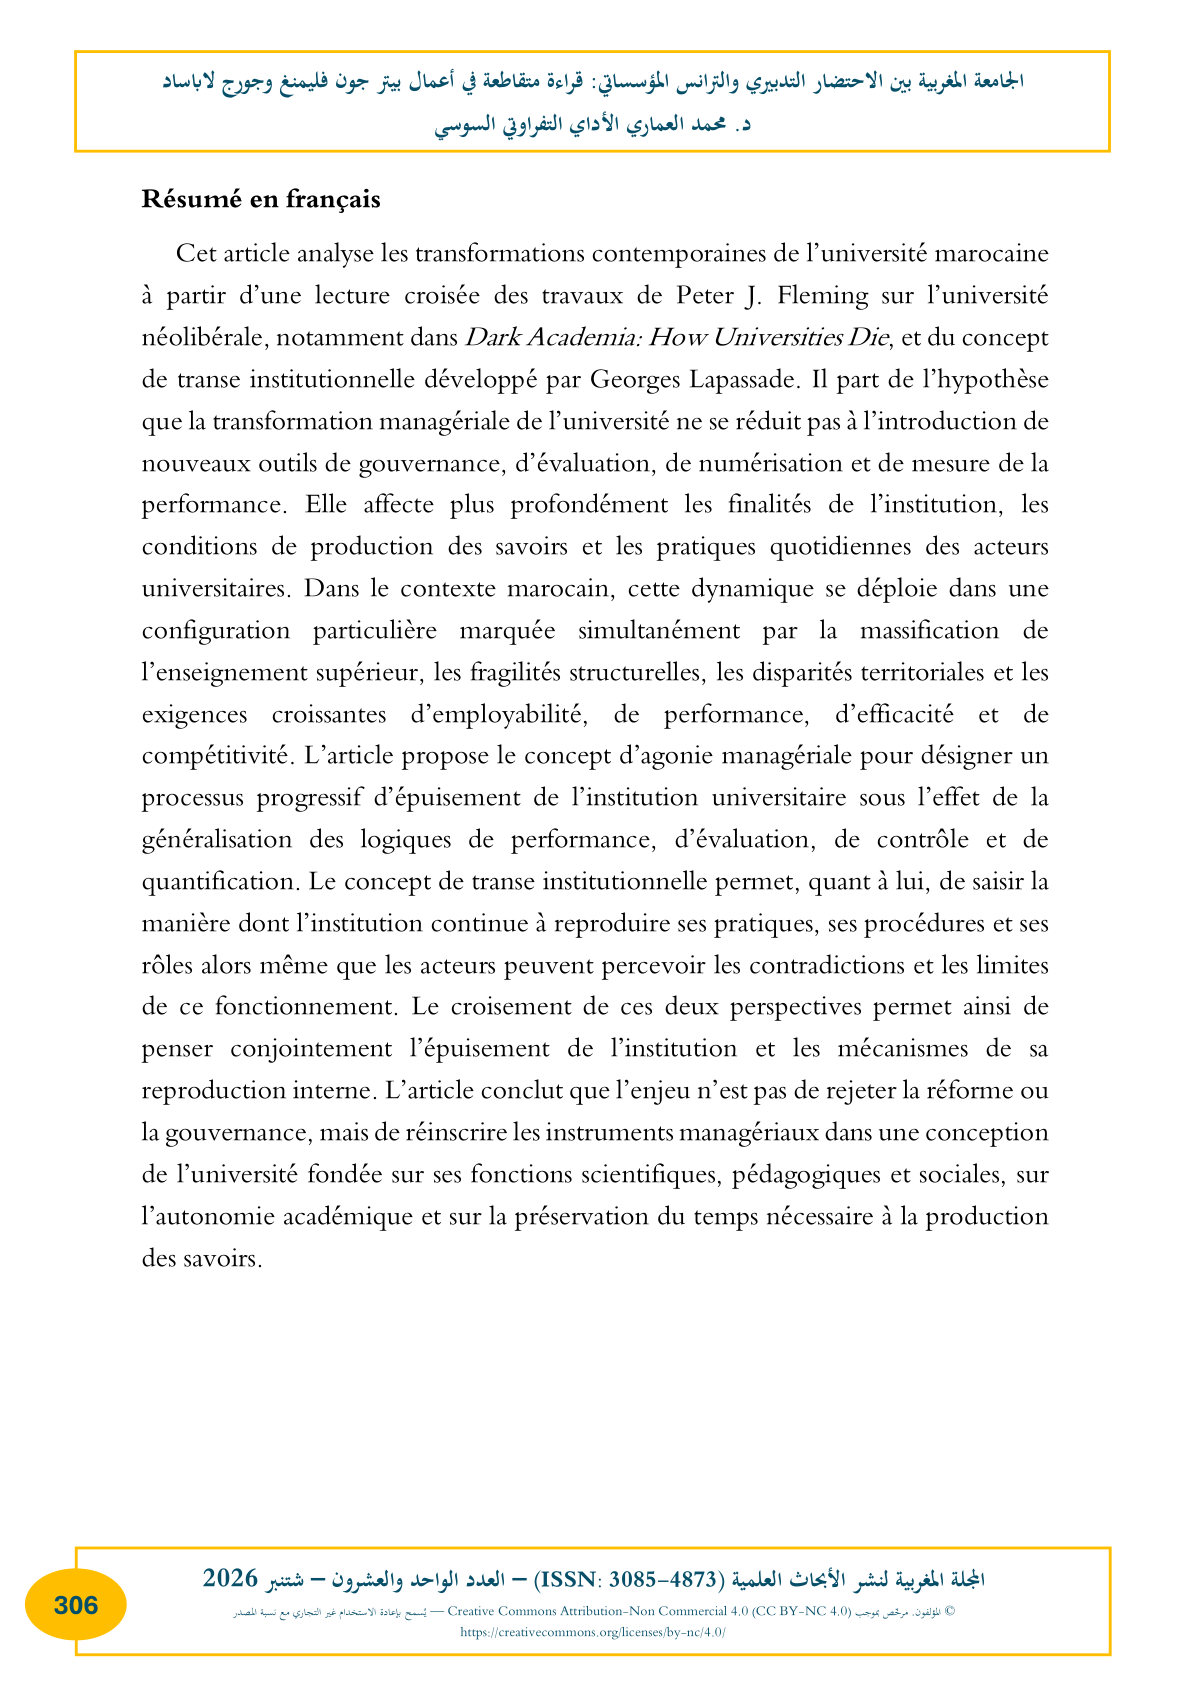

In [ ]:
# Vérifier visuellement le PDF de l'article 484

import pymupdf
from PIL import Image
from IPython.display import display
import os

# Sélectionner l'article 484
article_id = "484"

article_pdf_row = df_rmprs_pdf_metadata[
    df_rmprs_pdf_metadata["article_id"].astype(str) == article_id
].iloc[0]

pdf_url_484 = article_pdf_row["pdf_url"]

print("Article :", article_pdf_row["title"])
print("Langue déclarée :", article_pdf_row["declared_language"])
print("URL PDF :", pdf_url_484)

# Télécharger le PDF dans le dossier de travail
pdf_path_484 = "rmprs_pdfs/article_484.pdf"

pdf_response = session.get(pdf_url_484, timeout=60)
pdf_response.raise_for_status()

with open(pdf_path_484, "wb") as file:
    file.write(pdf_response.content)

print("\nTaille du PDF :",
      round(os.path.getsize(pdf_path_484) / (1024 * 1024), 2),
      "Mo")

# Ouvrir le document et afficher sa deuxième page
pdf_document_484 = pymupdf.open(pdf_path_484)

print("Nombre de pages :", len(pdf_document_484))

page_index = min(1, len(pdf_document_484) - 1)
page = pdf_document_484[page_index]

pixmap = page.get_pixmap(matrix=pymupdf.Matrix(2, 2))

page_image = Image.frombytes(
    "RGB",
    [pixmap.width, pixmap.height],
    pixmap.samples
)

print("\nAperçu de la page", page_index + 1, ":")
display(page_image)

### 4.3 Extraction directe du texte

On teste d'abord la lecture du texte encodé dans le PDF, avec PyMuPDF puis avec pdfplumber. Avec PyMuPDF, le texte arabe sort sous forme de caractères de présentation (lettres isolées ou liées) difficilement exploitables. Avec pdfplumber, les mots sont inversés et des marqueurs `(cid:…)` apparaissent à la place de certains caractères. Cette extraction n'est donc pas retenue.

In [ ]:
# Extraire le texte du PDF 484

pdf_document_484 = pymupdf.open(pdf_path_484)

text_484 = "\n".join(
    page.get_text("text")
    for page in pdf_document_484
)

# Compter les caractères arabes et latins
arabic_chars_484 = re.findall(
    r"[\u0600-\u06FF\u0750-\u077F\u08A0-\u08FF]",
    text_484
)

latin_chars_484 = re.findall(
    r"[A-Za-z]",
    text_484
)

print("--- QUALITÉ DE L'EXTRACTION ---")

print("Nombre de pages :", len(pdf_document_484))
print("Nombre total de caractères :", len(text_484))
print("Nombre de caractères arabes :", len(arabic_chars_484))
print("Nombre de caractères latins :", len(latin_chars_484))

if len(text_484) > 0:
    print(
        "Proportion de caractères arabes :",
        round(len(arabic_chars_484) / len(text_484) * 100, 2),
        "%"
    )

print("\n--- APERÇU DU TEXTE EXTRAIT ---")
print(text_484[:4000])

pdf_document_484.close()

--- QUALITÉ DE L'EXTRACTION ---
Nombre de pages : 21
Nombre total de caractères : 61690
Nombre de caractères arabes : 12441
Nombre de caractères latins : 8009
Proportion de caractères arabes : 20.17 %

--- APERÇU DU TEXTE EXTRAIT ---
 
 لةĐا اﳌﻐﺮﺑﻴة ﻟﻨﺸﺮ اﻷﲝﺎث اﻟﻌل ةﻤﻴ 
(ISSN: 3085-4873)
 – اﻟﻌﺪد 
 و اﻟﻮاﺣﺪ اﻟﻌﺸﺮون  – 
 ﺷﺘﻨﱪ 
2026
  
 ©اﳌﺆﻟﻔﻮن .ﺺّﻣﺮﺧ ﲟﻮﺟﺐ 
Creative Commons Attribution-Non Commercial 4.0 (CC BY-NC 4.0)
 
—
 
 ﺴﻤﺢُﻳ 
 عادةϵ
 اﻻﺳﺘﺨﺪام ﻏﲑ اﻟﺘﺠاري ﻣﻊ ﻧﺴﺒﺔ 
 اﳌﺼﺪر 
https://creativecommons.org/licenses/by-nc/4.0 / 
اﳉﺎﻣﻌة اﳌﻐﺮﺑﻴة ﺑﲔ اﻻﺣﺘﻀﺎر اﻟﺘﺪﺑﲑي واﻟﱰاﻧﺲ اﳌﺆﺳﺴﺎﰐ :ﺳﺎدʪقﺮاءة ﻣﺘقﺎطﻌة ﰲ أعﻤﺎل ﺑﻴﱰ جﻮن فلﻴﻤﻨغ وجﻮرج ﻻ  
.د
اﻟﺴﻮﺳﻲ اﻟﺘﻔﺮاوﰐ اﻷداي اﻟﻌﻤﺎري ﳏﻤﺪ 
305
 
  
  
 
 
 
 
اﳌلﺨﺺ ﻟﻌﺮﺑﻴةʪ
 
ﻳﺘﻨاول ﻫﺬا اﳌﻘال اﻟﺘﺤﻮﻻت اﻟﱵ ﺗﻌﺮﻓﻬا اﳉاﻣﻌﺔ اﳌﻐﺮﺑﻴﺔ ﰲ ﺳﻴاق اﻹﺻﻼﺣات اﳌﻌاﺻﺮة ﻹعادة ﺗﻨﻈﻴﻢ اﻟﺘﻌﻠﻴﻢ اﻟﻌاﱄ واﻟﺒﺤﺚ 
،اﻟﻌﻠﻤﻲ ﻣﻦ ﺧﻼل ﻗﺮاءة ﻣﺘﻘاﻃﻌﺔ ﺑﲔ أﻃﺮوﺣات ﺑﻴﱰ 
.ج ﻓﻠﻴﻤﻨﻎ ﺣﻮل اﳉاﻣﻌﺔ اﻟﻨﻴﻮﻟﻴﱪاﻟﻴﺔ ﰲ ﻛﺘاﺑﻪ  
Academia:
 
Dark
Die
 
Universities
 
How
، وﻣﻔﻬﻮم اﻟﱰاﻧﺲ اﳌﺆﺳﺴاﰐ ﻟﺪى ﺟﻮرج ﺳادʪﻻ. وﻳﻨﻄﻠﻖ اﳌﻘال ﻣ

In [ ]:
# Installer pdfplumber
!pip -q install pdfplumber

import pdfplumber
import unicodedata

# Extraire le texte de toutes les pages du PDF
text_484_pdfplumber = ""

with pdfplumber.open(pdf_path_484) as pdf:
    for page in pdf.pages:
        page_text = page.extract_text() or ""
        text_484_pdfplumber += page_text + "\n"

# Normaliser le texte
text_484_pdfplumber = unicodedata.normalize(
    "NFKC",
    text_484_pdfplumber
)

# Fonction pour compter les caractères suspects
def is_suspicious(char):
    code = ord(char)

    return (
        0x0250 <= code <= 0x02FF
        or 0x0370 <= code <= 0x052F
        or 0xE000 <= code <= 0xF8FF
        or code == 0xFFFD
    )

# Calculer les statistiques
suspicious_count = sum(
    1 for char in text_484_pdfplumber
    if is_suspicious(char)
)

arabic_count = sum(
    1 for char in text_484_pdfplumber
    if (
        "\u0600" <= char <= "\u06FF"
        or "\u0750" <= char <= "\u077F"
        or "\u08A0" <= char <= "\u08FF"
    ) and char.isalpha()
)

total_letters = sum(
    1 for char in text_484_pdfplumber
    if char.isalpha()
)

arabic_ratio_pdfplumber = (
    arabic_count / total_letters
    if total_letters > 0 else 0
)

print("--- EXTRACTION AVEC PDFPLUMBER ---")
print("Nombre de caractères :", len(text_484_pdfplumber))
print("Caractères suspects :", suspicious_count)
print("Lettres arabes :", arabic_count)
print("Proportion de lettres arabes :",
      round(arabic_ratio_pdfplumber * 100, 2), "%")

print("\n--- APERÇU DU TEXTE ---")
print(text_484_pdfplumber[:2500])

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
--- EXTRACTION AVEC PDFPLUMBER ---
Nombre de caractères : 66590
Caractères suspects : 22
Lettres arabes : 41873
Proportion de lettres arabes : 81.74 %

--- APERÇU DU TEXTE ---
داس(cid:682)لا جروجو غنميلف نوج تريب لامعأ في ةعطاقتم ةءارق :تياسسؤلما سناترلاو ييربدتلا راضتحلاا ينب ةيبرغلما ةعمالجا
ي سوسلا تيوارفتلا يادلأا يرامعلا دممح .د
:تياسسؤلما سناترلاو ييربدتلا راضتحلاا ينب ةيبرغلما ةعمالجا
داس(cid:682)لا جروجو غنميلف نوج تريب لامعأ في ةعطاقتم ةءارق
ي سوسلا تيوارفتلا يادلأا يرامعلا دممح .د
ريداك(cid:997) رهز نبإ ةعمابج عامتجلاا ملع ذاتسأ
ة يبرغلما ةكلملما
ةيبرعل(cid:682) صخللما
ثحبلاو لياعلا ميلعتلا ميظنت ةداعلإ ةرصاعلما تاحلاصلإا قايس في ةيبرغلما ةعمالجا اهفرعت تيلا تلاوحتلا لاقلما اذه لوانتي
Dark Academia: هباتك في ةيلاب

### 4.4 Reconnaissance optique de caractères

Chaque page est convertie en image à 300 DPI, puis lue par Tesseract avec les modèles arabe et français. Le résultat brut est conservé page par page dans `pages_ocr_484`. Cette étape prend quelques minutes.

In [ ]:
import pymupdf
import pytesseract
from PIL import Image

# Ouvrir le PDF de l'article 484
doc_ocr_full_484 = pymupdf.open(pdf_path_484)

# Liste qui contiendra le texte OCR de chaque page
pages_ocr_484 = []

# Parcourir toutes les pages du document
for page_number, page in enumerate(doc_ocr_full_484):

    # Convertir la page PDF en image avec une résolution de 300 DPI
    pix = page.get_pixmap(dpi=300)

    image = Image.frombytes(
        "RGB",
        [pix.width, pix.height],
        pix.samples
    )

    # Extraire le texte en arabe et en français
    page_text = pytesseract.image_to_string(
        image,
        lang="ara+fra",
        config="--psm 3"
    )

    # Conserver le résultat de cette page
    pages_ocr_484.append(page_text)

    print(f"Page {page_number + 1}/{len(doc_ocr_full_484)} traitée")

# Fermer le PDF
doc_ocr_full_484.close()

# Réunir les textes de toutes les pages
text_484_ocr_raw = "\n\n".join(pages_ocr_484)

# Compter les caractères arabes
arabic_chars_484 = sum(
    1 for char in text_484_ocr_raw
    if "\u0600" <= char <= "\u06FF"
    or "\u0750" <= char <= "\u077F"
    or "\u08A0" <= char <= "\u08FF"
)

# Compter les caractères alphabétiques
all_letters_484 = sum(
    1 for char in text_484_ocr_raw
    if char.isalpha()
)

# Calculer la proportion de caractères arabes
arabic_ratio_484 = (
    arabic_chars_484 / all_letters_484
    if all_letters_484 > 0 else 0
)

print("\n--- BILAN DE L'OCR ---")
print("Nombre de pages :", len(pages_ocr_484))
print("Nombre de caractères :", len(text_484_ocr_raw))
print("Nombre de caractères arabes :", arabic_chars_484)
print("Proportion de caractères arabes :", round(arabic_ratio_484 * 100, 2), "%")

# Afficher un extrait du texte complet
print("\n--- EXTRAIT DU TEXTE OCR ---\n")
print(text_484_ocr_raw[:4000])

Page 1/21 traitée
Page 2/21 traitée
Page 3/21 traitée
Page 4/21 traitée
Page 5/21 traitée
Page 6/21 traitée
Page 7/21 traitée
Page 8/21 traitée
Page 9/21 traitée
Page 10/21 traitée
Page 11/21 traitée
Page 12/21 traitée
Page 13/21 traitée
Page 14/21 traitée
Page 15/21 traitée
Page 16/21 traitée
Page 17/21 traitée
Page 18/21 traitée
Page 19/21 traitée
Page 20/21 traitée
Page 21/21 traitée

--- BILAN DE L'OCR ---
Nombre de pages : 21
Nombre de caractères : 63345
Nombre de caractères arabes : 41360
Proportion de caractères arabes : 82.79 %

--- EXTRAIT DU TEXTE OCR ---

الجامعة المغربية بين الاحتضار التدبيري والترادنس المؤسساني: قراءة متقاطعة في أعمال بيتر جون فليمنغ وجورج لاباساد

د. محمد العماري الأداي التفراوق السوسي

الجامعة المغربية بين الاحتضار التدبيري والترانس المؤسساق:
قراءة متقاطعة في أعمال بيتر جون فليمنغ وجورج لاباساد
د. محمد العماري الأداي التفراوقي السوسى
أستاذ علم الاجتماع بجامعة إبن زهر بأكادير
المملكة المغربية

اللخص بالعربية

يتناول هذا المقال التحولات التي تعرفها الجامعة

### 4.5 Sélection des pages arabes

La proportion de lettres arabes par page montre que les pages 2 et 3 (résumés en français et en anglais) et les pages 19 à 21 (références et résumés) ne sont pas en arabe. On conserve la page 1 (titre et résumé arabe) et les pages 4 à 18 (corps de l'article et conclusion).

In [ ]:
# Analyser séparément le texte OCR de chaque page

page_stats_484 = []

for page_number, page_text in enumerate(pages_ocr_484, start=1):

    # Compter les caractères alphabétiques
    total_letters = sum(
        1 for char in page_text
        if char.isalpha()
    )

    # Compter les caractères arabes
    arabic_letters = sum(
        1 for char in page_text
        if "\u0600" <= char <= "\u06FF"
        or "\u0750" <= char <= "\u077F"
        or "\u08A0" <= char <= "\u08FF"
    )

    # Calculer la proportion arabe
    ratio = (
        arabic_letters / total_letters
        if total_letters > 0 else 0
    )

    page_stats_484.append({
        "page": page_number,
        "characters": len(page_text),
        "arabic_characters": arabic_letters,
        "arabic_percentage": round(ratio * 100, 2)
    })

# Créer un tableau récapitulatif
df_page_stats_484 = pd.DataFrame(page_stats_484)

display(df_page_stats_484)

# Afficher les pages les moins riches en caractères arabes
print("\n--- Pages avec la plus faible proportion arabe ---")

display(
    df_page_stats_484.sort_values(
        by="arabic_percentage",
        ascending=True
    ).head(8)
)

,page,characters,arabic_characters,arabic_percentage
0,1,2150,1612,92.86
1,2,2432,234,11.74
2,3,2348,234,12.05
3,4,3745,2731,92.33
4,5,3796,2851,95.13
5,6,3570,2648,93.97
6,7,3766,2842,94.80
7,8,3435,2624,94.59
8,9,3694,2850,96.15
9,10,3554,2711,95.49



--- Pages avec la plus faible proportion arabe ---


,page,characters,arabic_characters,arabic_percentage
1,2,2432,234,11.74
2,3,2348,234,12.05
19,20,2004,248,17.44
18,19,1971,239,17.78
20,21,1063,237,31.52
17,18,1420,980,89.91
3,4,3745,2731,92.33
0,1,2150,1612,92.86


In [ ]:
# Sélectionner la page 1 et les pages 4 à 18
# Attention : Python commence à compter les indices à partir de 0.

pages_ar_selected_484 = (
    [pages_ocr_484[0]]
    + pages_ocr_484[3:18]
)

# Réunir les pages sélectionnées
text_484_ar_candidate = "\n\n".join(
    pages_ar_selected_484
)

# Calculer quelques statistiques
arabic_chars = sum(
    1 for char in text_484_ar_candidate
    if "\u0600" <= char <= "\u06FF"
    or "\u0750" <= char <= "\u077F"
    or "\u08A0" <= char <= "\u08FF"
)

total_chars = len(text_484_ar_candidate)

print("--- TEXTE ARABE SÉLECTIONNÉ ---")
print("Nombre de pages :", len(pages_ar_selected_484))
print("Nombre de caractères :", total_chars)
print("Nombre de caractères arabes :", arabic_chars)

print("\n--- DÉBUT DU TEXTE ---\n")
print(text_484_ar_candidate[:3000])

print("\n--- FIN DU TEXTE ---\n")
print(text_484_ar_candidate[-2000:])

--- TEXTE ARABE SÉLECTIONNÉ ---
Nombre de pages : 16
Nombre de caractères : 53517
Nombre de caractères arabes : 40168

--- DÉBUT DU TEXTE ---

الجامعة المغربية بين الاحتضار التدبيري والترادنس المؤسساني: قراءة متقاطعة في أعمال بيتر جون فليمنغ وجورج لاباساد

د. محمد العماري الأداي التفراوق السوسي

الجامعة المغربية بين الاحتضار التدبيري والترانس المؤسساق:
قراءة متقاطعة في أعمال بيتر جون فليمنغ وجورج لاباساد
د. محمد العماري الأداي التفراوقي السوسى
أستاذ علم الاجتماع بجامعة إبن زهر بأكادير
المملكة المغربية

اللخص بالعربية

يتناول هذا المقال التحولات التي تعرفها الجامعة المغربية في سياق الإصلاحات المعاصرة لإعادة تنظيم التعليم ‎ll‏ والبحث
العلمي» من خلال قراءة متقاطعة بين أطروحات بيتر ج. فليمنغ حول الجامعة النيوليرالية في ‎Dark Academia: as‏
‎ÜUniversites Die‏ 1170177» ومفهوم الترانس المؤسساتٍ لدى جورج لاباساد. وينطلق المقال من فرضية أساسية مفادها أن
التحول التديري للجامعة لا يقتصر على إدخال أدوات جديدة للحكامة والتقييم والرقمنة وقياس الأداء» بل يعيد تشكيل معنى
المؤسسة الجامعية ووظائفها وعمل 

### 4.6 Nettoyage du texte OCR

**Éléments éditoriaux répétés.** L'OCR reprend sur chaque page l'en-tête et le pied de page (titre de l'article, nom de l'auteur, nom de la revue, numéro, licence). On repère d'abord les lignes répétées, puis on les supprime.

In [ ]:
from collections import Counter

# Séparer le texte en lignes
lines_484 = [
    line.strip()
    for line in text_484_ar_candidate.splitlines()
    if line.strip()
]

# Compter les lignes identiques
line_counts_484 = Counter(lines_484)

# Afficher les lignes qui apparaissent au moins 3 fois
repeated_lines_484 = [
    (line, count)
    for line, count in line_counts_484.items()
    if count >= 3
]

# Trier par fréquence décroissante
repeated_lines_484.sort(
    key=lambda item: item[1],
    reverse=True
)

print("Nombre total de lignes non vides :", len(lines_484))
print("Nombre de lignes répétées au moins 3 fois :", len(repeated_lines_484))

print("\n--- LIGNES RÉPÉTÉES ---\n")

for line, count in repeated_lines_484:
    print(f"Répétée {count} fois :")
    print(line[:300])
    print("-" * 60)

Nombre total de lignes non vides : 511
Nombre de lignes répétées au moins 3 fois : 7

--- LIGNES RÉPÉTÉES ---

Répétée 16 fois :
الجامعة المغربية بين الاحتضار التدبيري والترادنس المؤسساني: قراءة متقاطعة في أعمال بيتر جون فليمنغ وجورج لاباساد
------------------------------------------------------------
Répétée 16 fois :
د. محمد العماري الأداي التفراوق السوسي
------------------------------------------------------------
Répétée 15 fois :
‏يُسمح بإعادة الاستخدام غير التجاري مع نسبة المصدر‎ — Creative Commons Attribution-Non Commercial 4.0 (CC BY-NC 4.0( Lise ‏المؤلفون. مرخص‎ ©
------------------------------------------------------------
Répétée 12 fois :
2026 ‏العدد الواحد والعشرون - شتنبر‎ — (ISSN: 3085-4873) ‏الأبحاث العلمية‎ LAS ‏المغربية‎ Le!
------------------------------------------------------------
Répétée 12 fois :
https://creativecommons.org/licenses/by-nc/4.0/
------------------------------------------------------------
Répétée 4 fois :
‎2026 ‏العدد الواحد والعشرون - شتنبر‎ — (I

In [ ]:
import re

# Créer une copie du texte sélectionné
text_484_no_headers = text_484_ar_candidate

# Définir les éléments éditoriaux à retirer
editorial_patterns_484 = [
    # URL de la licence Creative Commons
    r"https?://creativecommons\.org/licenses/by-nc/4\.0/?",

    # Mention de la licence
    r".*Creative Commons Attribution-Non Commercial 4\.0.*",

    # En-têtes contenant les informations de la revue
    r".*2026.*العدد الواحد والعشرون.*",

    # Titre répété
    r"الجامعة المغربية بين الاحتضار التدبيري.*جورج لاباساد",

    # Nom de l'auteur répété
    r"د\.\s*محمد العماري الأداي التفراوق[^\n]*",
]

# Retirer les lignes éditoriales correspondantes
for pattern in editorial_patterns_484:
    text_484_no_headers = re.sub(
        pattern,
        "",
        text_484_no_headers,
        flags=re.MULTILINE
    )

# Supprimer les espaces excessifs
text_484_no_headers = re.sub(
    r"\n{3,}",
    "\n\n",
    text_484_no_headers
)

# Afficher les statistiques
print("--- APRÈS NETTOYAGE ÉDITORIAL ---")
print("Caractères avant :", len(text_484_ar_candidate))
print("Caractères après :", len(text_484_no_headers))
print("Caractères retirés :", len(text_484_ar_candidate) - len(text_484_no_headers))

print("\n--- DÉBUT DU TEXTE NETTOYÉ ---\n")
print(text_484_no_headers[:2500])

print("\n--- FIN DU TEXTE NETTOYÉ ---\n")
print(text_484_no_headers[-1500:])

--- APRÈS NETTOYAGE ÉDITORIAL ---
Caractères avant : 53517
Caractères après : 46446
Caractères retirés : 7071

--- DÉBUT DU TEXTE NETTOYÉ ---



الجامعة المغربية بين الاحتضار التدبيري والترانس المؤسساق:
قراءة متقاطعة في أعمال بيتر جون فليمنغ وجورج لاباساد

أستاذ علم الاجتماع بجامعة إبن زهر بأكادير
المملكة المغربية

اللخص بالعربية

يتناول هذا المقال التحولات التي تعرفها الجامعة المغربية في سياق الإصلاحات المعاصرة لإعادة تنظيم التعليم ‎ll‏ والبحث
العلمي» من خلال قراءة متقاطعة بين أطروحات بيتر ج. فليمنغ حول الجامعة النيوليرالية في ‎Dark Academia: as‏
‎ÜUniversites Die‏ 1170177» ومفهوم الترانس المؤسساتٍ لدى جورج لاباساد. وينطلق المقال من فرضية أساسية مفادها أن
التحول التديري للجامعة لا يقتصر على إدخال أدوات جديدة للحكامة والتقييم والرقمنة وقياس الأداء» بل يعيد تشكيل معنى
المؤسسة الجامعية ووظائفها وعمل الفاعلين داخلها. وفي السياق المغربي» تتخذ هذه التحولات طابعًا أكثر تعقيدًا بفعل تداخل
تحديات التوسع الجماهيريء والهشاشة البنيوية» والتفاوتات ‎él‏ وضغط قابلية التشغيل» مع تصاعد متطلبات الأداء 

**Normalisation.** On reconstitue le titre et le nom de l'auteur à partir des métadonnées vérifiées de la page, puis on supprime les marqueurs Unicode de direction (LRM et RLM) et une liste de fragments parasites identifiés manuellement après examen de leur contexte. Le titre du résumé, mal reconnu (« اللخص »), est corrigé (« الملخص »).

In [ ]:
# Informations bibliographiques vérifiées sur la page de l'article
title_484 = (
    "الجامعة المغربية بين الاحتضار التدبيري والترانس المؤسساتي: "
    "قراءة متقاطعة في أعمال بيتر جون فليمنغ وجورج لاباساد"
)

author_484 = "د. محمد العماري الأداي التفراوتي السوسي"

# Construire une version structurée sans modifier le texte nettoyé
text_484_structured = (
    title_484
    + "\n"
    + author_484
    + "\n\n"
    + text_484_no_headers.strip()
)

# Vérifier la présence des informations bibliographiques
print("--- VÉRIFICATION DES MÉTADONNÉES ---")
print("Titre présent :", title_484 in text_484_structured)
print("Auteur présent :", author_484 in text_484_structured)

# Vérifier les anciennes répétitions
print("\n--- VÉRIFICATION DES ÉLÉMENTS ÉDITORIAUX ---")

print(
    "Nombre de lignes contenant le titre :",
    text_484_structured.count(title_484)
)

print(
    "Nombre de mentions de l'URL de licence :",
    text_484_structured.count("creativecommons.org/licenses/by-nc/4.0")
)

# Afficher les statistiques
print("\n--- STATISTIQUES ---")
print("Texte OCR sélectionné :", len(text_484_ar_candidate))
print("Texte nettoyé :", len(text_484_no_headers))
print("Texte structuré :", len(text_484_structured))

print("\n--- DÉBUT DU TEXTE STRUCTURÉ ---\n")
print(text_484_structured[:1200])

--- VÉRIFICATION DES MÉTADONNÉES ---
Titre présent : True
Auteur présent : True

--- VÉRIFICATION DES ÉLÉMENTS ÉDITORIAUX ---
Nombre de lignes contenant le titre : 1
Nombre de mentions de l'URL de licence : 0

--- STATISTIQUES ---
Texte OCR sélectionné : 53517
Texte nettoyé : 46446
Texte structuré : 46595

--- DÉBUT DU TEXTE STRUCTURÉ ---

الجامعة المغربية بين الاحتضار التدبيري والترانس المؤسساتي: قراءة متقاطعة في أعمال بيتر جون فليمنغ وجورج لاباساد
د. محمد العماري الأداي التفراوتي السوسي

الجامعة المغربية بين الاحتضار التدبيري والترانس المؤسساق:
قراءة متقاطعة في أعمال بيتر جون فليمنغ وجورج لاباساد

أستاذ علم الاجتماع بجامعة إبن زهر بأكادير
المملكة المغربية

اللخص بالعربية

يتناول هذا المقال التحولات التي تعرفها الجامعة المغربية في سياق الإصلاحات المعاصرة لإعادة تنظيم التعليم ‎ll‏ والبحث
العلمي» من خلال قراءة متقاطعة بين أطروحات بيتر ج. فليمنغ حول الجامعة النيوليرالية في ‎Dark Academia: as‏
‎ÜUniversites Die‏ 1170177» ومفهوم الترانس المؤسساتٍ لدى جورج لاباساد. وينطلق المقال من فرضية أس

In [ ]:
# Conserver une copie du texte avant cette opération
text_484_before_direction_cleanup = text_484_structured

# Supprimer uniquement les marqueurs Unicode de direction
direction_marks = [
    "\u200e",  # LRM : Left-to-Right Mark
    "\u200f"   # RLM : Right-to-Left Mark
]

text_484_direction_clean = text_484_structured

for mark in direction_marks:
    text_484_direction_clean = text_484_direction_clean.replace(mark, "")

# Vérifications
print("--- VÉRIFICATION DU NETTOYAGE ---")

print(
    "Nombre de marqueurs restants :",
    sum(text_484_direction_clean.count(mark) for mark in direction_marks)
)

print(
    "Longueur avant :",
    len(text_484_before_direction_cleanup)
)

print(
    "Longueur après :",
    len(text_484_direction_clean)
)

print(
    "Différence :",
    len(text_484_before_direction_cleanup) - len(text_484_direction_clean)
)

print(
    "Titre conservé :",
    title_484 in text_484_direction_clean
)

print(
    "Auteur conservé :",
    author_484 in text_484_direction_clean
)

print("\n--- APERÇU ---\n")
print(text_484_direction_clean[:1800])

--- VÉRIFICATION DU NETTOYAGE ---
Nombre de marqueurs restants : 0
Longueur avant : 46595
Longueur après : 46161
Différence : 434
Titre conservé : True
Auteur conservé : True

--- APERÇU ---

الجامعة المغربية بين الاحتضار التدبيري والترانس المؤسساتي: قراءة متقاطعة في أعمال بيتر جون فليمنغ وجورج لاباساد
د. محمد العماري الأداي التفراوتي السوسي

الجامعة المغربية بين الاحتضار التدبيري والترانس المؤسساق:
قراءة متقاطعة في أعمال بيتر جون فليمنغ وجورج لاباساد

أستاذ علم الاجتماع بجامعة إبن زهر بأكادير
المملكة المغربية

اللخص بالعربية

يتناول هذا المقال التحولات التي تعرفها الجامعة المغربية في سياق الإصلاحات المعاصرة لإعادة تنظيم التعليم ll والبحث
العلمي» من خلال قراءة متقاطعة بين أطروحات بيتر ج. فليمنغ حول الجامعة النيوليرالية في Dark Academia: as
ÜUniversites Die 1170177» ومفهوم الترانس المؤسساتٍ لدى جورج لاباساد. وينطلق المقال من فرضية أساسية مفادها أن
التحول التديري للجامعة لا يقتصر على إدخال أدوات جديدة للحكامة والتقييم والرقمنة وقياس الأداء» بل يعيد تشكيل معنى
المؤسسة الجامعية ووظائفها وع

In [ ]:
from collections import Counter

# Conserver une copie avant le nettoyage ciblé
text_484_before_ocr_cleanup = text_484_direction_clean

# Fragments OCR identifiés comme parasites après examen du contexte
ocr_artifacts_484 = [
    "OÙ",
    "cell",
    "Go",
    "dj",
    "Gé",
    "JUN",
    "Ge",
    "Rai",
    "ll",
    "cg",
    "SU",
    "lee",
    "col M",
    "Gb",
    "dalle",
    "ailes",
    "él",
    "alle",
    "ÜUniversites Die",
    "1170177"
]

# Supprimer les fragments en respectant les limites des mots
text_484_ocr_clean = text_484_direction_clean
removed_counts_484 = {}

for artifact in sorted(ocr_artifacts_484, key=len, reverse=True):
    pattern = r"(?<!\w)" + re.escape(artifact) + r"(?!\w)"

    matches = re.findall(
        pattern,
        text_484_ocr_clean,
        flags=re.IGNORECASE
    )

    if matches:
        removed_counts_484[artifact] = len(matches)
        text_484_ocr_clean = re.sub(
            pattern,
            " ",
            text_484_ocr_clean,
            flags=re.IGNORECASE
        )

# Réduire les espaces multiples sans supprimer les paragraphes
text_484_ocr_clean = re.sub(r"[ \t]+", " ", text_484_ocr_clean)
text_484_ocr_clean = re.sub(r" *\n *", "\n", text_484_ocr_clean)
text_484_ocr_clean = re.sub(r"\n{3,}", "\n\n", text_484_ocr_clean)

# Vérifications
print("--- FRAGMENTS SUPPRIMÉS ---")

for artifact, count in removed_counts_484.items():
    print(f"{artifact} : {count}")

print("\n--- STATISTIQUES ---")
print("Longueur avant :", len(text_484_before_ocr_cleanup))
print("Longueur après :", len(text_484_ocr_clean))
print("Caractères retirés :",
      len(text_484_before_ocr_cleanup) - len(text_484_ocr_clean))

print("\n--- RÉFÉRENCES À CONSERVER ---")

references_to_check = [
    "Dark Academia",
    "How Universities Die",
    "Lapassade",
    "Savage",
    "Boumard",
    "Morley"
]

for reference in references_to_check:
    print(
        reference,
        ":",
        reference in text_484_ocr_clean
    )

print("\n--- APERÇU DU TEXTE NETTOYÉ ---\n")
print(text_484_ocr_clean[:1800])

--- FRAGMENTS SUPPRIMÉS ---
ÜUniversites Die : 1
1170177 : 1
col M : 1
dalle : 1
ailes : 1
cell : 3
alle : 1
JUN : 2
Rai : 1
lee : 1
OÙ : 14
Go : 3
dj : 3
Gé : 2
Ge : 2
ll : 1
cg : 1
SU : 1
Gb : 1
él : 1

--- STATISTIQUES ---
Longueur avant : 46161
Longueur après : 45988
Caractères retirés : 173

--- RÉFÉRENCES À CONSERVER ---
Dark Academia : True
How Universities Die : True
Lapassade : True
Savage : True
Boumard : True
Morley : True

--- APERÇU DU TEXTE NETTOYÉ ---

الجامعة المغربية بين الاحتضار التدبيري والترانس المؤسساتي: قراءة متقاطعة في أعمال بيتر جون فليمنغ وجورج لاباساد
د. محمد العماري الأداي التفراوتي السوسي

الجامعة المغربية بين الاحتضار التدبيري والترانس المؤسساق:
قراءة متقاطعة في أعمال بيتر جون فليمنغ وجورج لاباساد

أستاذ علم الاجتماع بجامعة إبن زهر بأكادير
المملكة المغربية

اللخص بالعربية

يتناول هذا المقال التحولات التي تعرفها الجامعة المغربية في سياق الإصلاحات المعاصرة لإعادة تنظيم التعليم والبحث
العلمي» من خلال قراءة متقاطعة بين أطروحات بيتر ج. فليمنغ حول الجامعة النيولي

In [ ]:
# Conserver une copie avant cette correction
text_484_before_title_correction = text_484_ocr_clean

# Corriger uniquement le titre du résumé
text_484_ocr_clean = text_484_ocr_clean.replace(
    "اللخص بالعربية",
    "الملخص بالعربية"
)

# Vérifier la correction
print("--- VÉRIFICATION DE LA CORRECTION ---")

print(
    "Ancienne forme présente :",
    "اللخص بالعربية" in text_484_ocr_clean
)

print(
    "Nouvelle forme présente :",
    text_484_ocr_clean.count("الملخص بالعربية") == 1
)

print("\n--- EXTRAIT CORRIGÉ ---\n")

lines = text_484_ocr_clean.splitlines()

for i, line in enumerate(lines):
    if "الملخص بالعربية" in line:
        print("\n".join(lines[max(0, i-2):i+4]))
        break

--- VÉRIFICATION DE LA CORRECTION ---
Ancienne forme présente : False
Nouvelle forme présente : True

--- EXTRAIT CORRIGÉ ---

المملكة المغربية

الملخص بالعربية

يتناول هذا المقال التحولات التي تعرفها الجامعة المغربية في سياق الإصلاحات المعاصرة لإعادة تنظيم التعليم والبحث
العلمي» من خلال قراءة متقاطعة بين أطروحات بيتر ج. فليمنغ حول الجامعة النيوليرالية في Dark Academia: as


**Fragments latins restants.** Les noms propres et références (Dark Academia, Lapassade, Savage, Boumard…) sont conservés. Après inspection du contexte de chaque fragment latin restant, ceux qui proviennent d'erreurs de reconnaissance de mots arabes sont supprimés ; les fragments d'une seule lettre sont conservés par précaution. Les mots arabes mal reconnus ne sont pas corrigés automatiquement.

In [ ]:
from collections import Counter
import re

# Créer une copie de sécurité avant la correction manuelle
text_484_before_manual_review = text_484_ocr_clean

# Extraire les mots contenant des caractères latins
latin_tokens_484 = re.findall(
    r"[A-Za-z][A-Za-z0-9’'-]*",
    text_484_before_manual_review
)

# Compter les occurrences de chaque mot
latin_token_counts_484 = Counter(latin_tokens_484)

print("--- INVENTAIRE DES FRAGMENTS LATINS ---")
print("Nombre total d'occurrences :", len(latin_tokens_484))
print("Nombre de fragments différents :", len(latin_token_counts_484))

print("\n--- FRAGMENTS LES PLUS FRÉQUENTS ---")
for token, count in latin_token_counts_484.most_common(60):
    print(f"{token} : {count}")

print("\n--- VÉRIFICATION DE LA COPIE DE SÉCURITÉ ---")
print("Copie créée :", text_484_before_manual_review == text_484_ocr_clean)
print("Longueur du texte :", len(text_484_before_manual_review))

--- INVENTAIRE DES FRAGMENTS LATINS ---
Nombre total d'occurrences : 237
Nombre de fragments différents : 164

--- FRAGMENTS LES PLUS FRÉQUENTS ---
Le : 10
Les : 6
Academia : 5
Us : 5
Dark : 4
A : 4
Universities : 4
Savage : 4
How : 3
Die : 3
Li : 3
l : 3
transe : 3
Morley : 3
en : 3
Je : 3
Boumard : 3
Hess : 3
Lapassade : 3
as : 2
x : 2
a : 2
LS : 2
Ross : 2
PACTE : 2
ESRI : 2
pl : 2
Jos : 2
ST : 2
ON : 2
SN : 2
le : 2
of : 2
Ji : 2
es : 2
des : 2
Vi : 1
du : 1
Ms : 1
Ja : 1
ef : 1
Die’ : 1
je : 1
YHow : 1
Leg : 1
ad : 1
code : 1
JM : 1
Came : 1
si : 1
di : 1
les : 1
SH : 1
VU : 1
cle : 1
h : 1
OU : 1
Ad : 1
I : 1
AIS : 1

--- VÉRIFICATION DE LA COPIE DE SÉCURITÉ ---
Copie créée : True
Longueur du texte : 45989


In [ ]:
# Références et expressions latines à préserver
protected_tokens_484 = {
    "dark",
    "academia",
    "how",
    "universities",
    "die",
    "fleming",
    "morley",
    "ross",
    "savage",
    "boumard",
    "hess",
    "lapassade",
    "pacte",
    "esri",
    "bourdieu",
    "en",
    "transe",
}

# Classer les fragments sans modifier le texte
protected_fragments_484 = {}
suspect_fragments_484 = {}

for token, count in latin_token_counts_484.items():
    if token.casefold() in protected_tokens_484:
        protected_fragments_484[token] = count
    else:
        suspect_fragments_484[token] = count

print("--- RÉFÉRENCES ET TERMES À PRÉSERVER ---")

for token, count in sorted(
    protected_fragments_484.items(),
    key=lambda item: item[0].casefold()
):
    print(f"{token} : {count}")

print("\n--- FRAGMENTS À EXAMINER ---")

for token, count in sorted(
    suspect_fragments_484.items(),
    key=lambda item: (-item[1], item[0].casefold())
):
    print(f"{token} : {count}")

print("\n--- BILAN ---")
print("Fragments protégés :", len(protected_fragments_484))
print("Fragments à examiner :", len(suspect_fragments_484))
print("Total :", len(protected_fragments_484) + len(suspect_fragments_484))

# Vérifier que le texte n'a pas été modifié
print(
    "Texte inchangé :",
    text_484_before_manual_review == text_484_ocr_clean
)

--- RÉFÉRENCES ET TERMES À PRÉSERVER ---
Academia : 5
Boumard : 3
Dark : 4
Die : 3
en : 3
ESRI : 2
Fleming : 1
Hess : 3
How : 3
Lapassade : 3
Morley : 3
PACTE : 2
Ross : 2
ROSS : 1
Savage : 4
transe : 3
Universities : 4

--- FRAGMENTS À EXAMINER ---
Le : 10
Les : 6
Us : 5
A : 4
Je : 3
l : 3
Li : 3
a : 2
as : 2
des : 2
es : 2
Ji : 2
Jos : 2
le : 2
LS : 2
of : 2
ON : 2
pl : 2
SN : 2
ST : 2
x : 2
abs : 1
ad : 1
Ad : 1
Ads : 1
AIS : 1
all : 1
ANS : 1
ARE : 1
Ass : 1
aus : 1
axe : 1
ball : 1
bat : 1
best : 1
Boul : 1
BU : 1
BUS : 1
CA : 1
cage : 1
cal : 1
cam : 1
Came : 1
ce : 1
ces : 1
Christine : 1
cl : 1
cle : 1
co : 1
code : 1
col : 1
cos : 1
cs : 1
CSN : 1
css : 1
D : 1
di : 1
Die’ : 1
Ds : 1
dt : 1
du : 1
dus : 1
ee : 1
ef : 1
Es : 1
Et : 1
EU : 1
G : 1
gi : 1
Groupes : 1
gui : 1
Gui : 1
GUN : 1
h : 1
Hs : 1
I : 1
ii : 1
institutions : 1
ISA : 1
IT : 1
Ja : 1
Jai : 1
je : 1
Jeu : 1
JIFleming : 1
JM : 1
Jo : 1
Ju : 1
L : 1
L'Universit : 1
La : 1
LA : 1
Lai : 1
LAS : 1
Last : 1
LB : 1
L

In [ ]:
# Créer une nouvelle copie pour le nettoyage final
text_484_final_candidate = text_484_before_manual_review

# Éléments bibliographiques et noms propres à préserver
protected_final_484 = {
    "christine", "lai", "saltorato",
    "groupes", "organisations", "institutions",
    "dark", "academia", "how", "universities", "die",
    "fleming", "morley", "ross", "savage",
    "boumard", "hess", "lapassade",
    "pacte", "esri", "bourdieu",
    "en", "transe", "l'universit"
}

removed_final_484 = {}

# Supprimer uniquement les fragments suspects de 2 lettres ou plus
for token in sorted(
    suspect_fragments_484,
    key=len,
    reverse=True
):
    if len(token) < 2 or token.casefold() in protected_final_484:
        continue

    pattern = r"(?<![A-Za-z])" + re.escape(token) + r"(?![A-Za-z])"

    count_before = len(re.findall(
        pattern, text_484_final_candidate, flags=re.IGNORECASE
    ))

    if count_before:
        text_484_final_candidate = re.sub(
            pattern,
            " ",
            text_484_final_candidate,
            flags=re.IGNORECASE
        )
        removed_final_484[token] = count_before

# Nettoyer les espaces sans supprimer la structure des paragraphes
text_484_final_candidate = re.sub(
    r"[ \t]+", " ", text_484_final_candidate
)
text_484_final_candidate = re.sub(
    r" *\n *", "\n", text_484_final_candidate
)
text_484_final_candidate = re.sub(
    r"\n{3,}", "\n\n", text_484_final_candidate
).strip()

# Vérifications
print("--- BILAN DU NETTOYAGE ---")
print("Longueur avant :", len(text_484_before_manual_review))
print("Longueur après :", len(text_484_final_candidate))
print("Fragments supprimés :", sum(removed_final_484.values()))

print("\n--- ÉLÉMENTS À PRÉSERVER ---")
for item in [
    "Christine", "Lai", "Saltorato",
    "Groupes", "organisations", "institutions",
    "Dark Academia", "How Universities Die",
    "Lapassade", "Savage", "Boumard"
]:
    print(f"{item} :", item.casefold() in text_484_final_candidate.casefold())

print("\n--- SAUVEGARDE ---")
print("Texte OCR original intact :",
      text_484_before_manual_review == text_484_ocr_clean)

--- BILAN DU NETTOYAGE ---
Longueur avant : 45989
Longueur après : 45422
Fragments supprimés : 160

--- ÉLÉMENTS À PRÉSERVER ---
Christine : True
Lai : True
Saltorato : True
Groupes : True
organisations : True
institutions : True
Dark Academia : True
How Universities Die : True
Lapassade : True
Savage : True
Boumard : True

--- SAUVEGARDE ---
Texte OCR original intact : True


**Contrôle final.** On vérifie la proportion de lettres arabes (99 % parmi les lettres arabes et latines) et la présence des éléments essentiels : titre, auteur, résumé, mots-clés, références principales et conclusion.

In [ ]:
# Calculer les statistiques du texte nettoyé
arabic_chars_final_484 = re.findall(
    r"[\u0600-\u06FF\u0750-\u077F\u08A0-\u08FF]",
    text_484_final_candidate
)

latin_chars_final_484 = re.findall(
    r"[A-Za-z]",
    text_484_final_candidate
)

total_letters_final_484 = (
    len(arabic_chars_final_484) + len(latin_chars_final_484)
)

arabic_ratio_final_484 = (
    len(arabic_chars_final_484) / total_letters_final_484
    if total_letters_final_484 else 0
)

# Vérifier les éléments essentiels
checks_final_484 = {
    "Titre de l'article": "الجامعة المغربية بين الاحتضار التدبيري",
    "Nom de l'auteur": "محمد العماري",
    "Résumé arabe": "الملخص بالعربية",
    "Mots-clés": "الكلمات المفتاحية",
    "Référence à Fleming": "فليمنغ",
    "Référence à Lapassade": "لاباساد",
    "Conclusion présente": "الجامعة المغربية اليوم"
}

print("--- STATISTIQUES FINALES ---")
print("Nombre de caractères :", len(text_484_final_candidate))
print("Nombre de mots :", len(text_484_final_candidate.split()))
print("Caractères arabes :", len(arabic_chars_final_484))
print("Caractères latins :", len(latin_chars_final_484))
print(f"Proportion de caractères arabes : {arabic_ratio_final_484:.2%}")

print("\n--- VÉRIFICATION DU CONTENU ---")
for label, expression in checks_final_484.items():
    print(f"{label} :", "Présent" if expression in text_484_final_candidate else "À vérifier")

print("\n--- APERÇU DU TEXTE ---")
print(text_484_final_candidate[:1200])
print("\n--- FIN DU TEXTE ---")
print(text_484_final_candidate[-1000:])

--- STATISTIQUES FINALES ---
Nombre de caractères : 45422
Nombre de mots : 7310
Caractères arabes : 36616
Caractères latins : 369
Proportion de caractères arabes : 99.00%

--- VÉRIFICATION DU CONTENU ---
Titre de l'article : Présent
Nom de l'auteur : Présent
Résumé arabe : Présent
Mots-clés : Présent
Référence à Fleming : Présent
Référence à Lapassade : Présent
Conclusion présente : Présent

--- APERÇU DU TEXTE ---
الجامعة المغربية بين الاحتضار التدبيري والترانس المؤسساتي: قراءة متقاطعة في أعمال بيتر جون فليمنغ وجورج لاباساد
د. محمد العماري الأداي التفراوتي السوسي

الجامعة المغربية بين الاحتضار التدبيري والترانس المؤسساق:
قراءة متقاطعة في أعمال بيتر جون فليمنغ وجورج لاباساد

أستاذ علم الاجتماع بجامعة إبن زهر بأكادير
المملكة المغربية

الملخص بالعربية

يتناول هذا المقال التحولات التي تعرفها الجامعة المغربية في سياق الإصلاحات المعاصرة لإعادة تنظيم التعليم والبحث
العلمي» من خلال قراءة متقاطعة بين أطروحات بيتر ج. فليمنغ حول الجامعة النيوليرالية في Dark Academia:
» ومفهوم الترانس المؤسساتٍ ل

### 4.7 Intégration de l'article 484

Le texte nettoyé est ajouté au dataset avec ses métadonnées (source, URL, licence CC BY-NC 4.0, score 9). La date est complétée à l'étape suivante.

In [ ]:
# Métadonnées vérifiées de l'article
article_484 = {
    "id": "RMPRS_484",
    "title": (
        "الجامعة المغربية بين الاحتضار التدبيري والترانس المؤسساتي: "
        "قراءة متقاطعة في أعمال بيتر جون فليمنغ وجورج لاباساد"
    ),
    "text": text_484_final_candidate,
    "source": RMPRS_SOURCE,
    "url": "https://rmprs.com/index.php/rmprs/article/view/484",
    "date": None,
    "language": "ar",
    "license": "CC BY-NC 4.0 (attribution requise, usage non commercial)",
    "score": 9
}

# Créer une ligne avec les mêmes colonnes que le dataset
df_article_484 = pd.DataFrame(
    [article_484],
    columns=df_dataset.columns
)

# Vérifier que l'article n'existe pas déjà
if article_484["id"] not in df_dataset["id"].values:
    df_dataset = pd.concat(
        [df_dataset, df_article_484],
        ignore_index=True
    )
    print("Article 484 ajouté au dataset.")
else:
    print("Article 484 déjà présent : aucun doublon ajouté.")

# Vérifications
print("\nNombre total de documents :", len(df_dataset))
print("Nombre de documents RMPRS :",
      df_dataset["id"].str.startswith("RMPRS_").sum())

print("\nDernier article ajouté :")
print(df_dataset[df_dataset["id"] == "RMPRS_484"][
    ["id", "title", "source", "language", "score"]
].to_string(index=False))

## 5. Articles RMPRS complémentaires (résumés)

Le texte complet des autres PDF nécessiterait un OCR long et bruité. Pour 13 des 14 autres articles de la catégorie « Forte », on retient donc le résumé arabe disponible dans les métadonnées, qui est un texte propre et directement exploitable. Chaque article reçoit un score de pertinence (8 ou 9) et sa date de publication est renseignée, ainsi que celle de l'article 484.

In [ ]:
# Scores de pertinence des articles RMPRS retenus (hors article 484)
scores_rmprs = {
    "419": 9, "360": 9, "361": 8, "192": 8, "206": 9,
    "418": 8, "127": 9, "129": 9, "130": 9, "14": 9,
    "175": 9, "420": 9, "421": 8
}

# Métadonnées de la revue indexées par identifiant d'article
meta_by_id = (
    df_rmprs_metadata
    .assign(article_id=df_rmprs_metadata["article_id"].astype(str))
    .drop_duplicates(subset="article_id")
    .set_index("article_id")
)

# Une ligne par article, construite à partir du résumé arabe
rmprs_rows = []
skipped = []

for article_id, score in scores_rmprs.items():

    meta = meta_by_id.loc[article_id]
    abstract = meta["abstract"]

    # Résumé absent ou trop court : article ignoré
    if not isinstance(abstract, str) or len(abstract.strip()) < 200:
        skipped.append(article_id)
        continue

    rmprs_rows.append({
        "id": "RMPRS_" + article_id,
        "title": meta["title"],
        "text": abstract.strip(),
        "source": RMPRS_SOURCE,
        "url": meta["url"],
        "date": meta["date"],
        "language": "ar",
        "license": "CC BY-NC 4.0 (attribution requise, usage non commercial)",
        "score": score
    })

df_rmprs_final = pd.DataFrame(rmprs_rows, columns=df_dataset.columns)

# Éviter les doublons avec les articles déjà présents
df_rmprs_to_add = df_rmprs_final[
    ~df_rmprs_final["id"].isin(df_dataset["id"])
].copy()

df_dataset = pd.concat(
    [df_dataset, df_rmprs_to_add],
    ignore_index=True
)

# Date de publication de l'article 484 (absente lors de son intégration)
if "484" in meta_by_id.index:
    df_dataset.loc[df_dataset["id"] == "RMPRS_484", "date"] = meta_by_id.loc["484", "date"]

# Vérifications
print("Articles RMPRS ajoutés :", len(df_rmprs_to_add))

if skipped:
    print("Articles ignorés (résumé absent ou trop court) :", skipped)

print("Taille actuelle du dataset :", len(df_dataset))
print("Identifiants dupliqués :", df_dataset["id"].duplicated().sum())
print("Dates manquantes :", df_dataset["date"].isna().sum())

print("\nRépartition des sources :")
display(df_dataset["source"].value_counts())

## 6. Textes peu pertinents (Wikipédia)

Les articles collectés traitent presque tous de l'éducation. Pour que les scores couvrent toute l'échelle de 0 à 10, on ajoute l'introduction de pages issues des mêmes recherches mais dont le titre n'évoque pas l'éducation (`df_other_articles`, section 2.3 ; les 80 premières pages sont utilisées). Ces pages n'ont pas de score manuel : leur score est calculé uniquement de façon automatique à l'étape 7. Le résultat est le corpus d'articles `df_all` (articles RMPRS, articles Wikipédia pertinents et pages peu pertinentes).

In [ ]:
def fetch_intros(pageids):
    rows = []
    for k in range(0, len(pageids), 20):
        batch = pageids[k:k+20]
        r = session.get(WIKIPEDIA_API, params={
            "action": "query", "format": "json", "pageids": "|".join(map(str, batch)),
            "prop": "extracts|info", "exintro": 1, "explaintext": 1,
            "exlimit": 20, "inprop": "url"}, timeout=60)
        r.raise_for_status()
        for p in r.json()["query"]["pages"].values():
            if p.get("extract"):
                rows.append({"id": f"WIKI_{p['pageid']}", "title": p["title"],
                             "text": p["extract"].strip(), "source": "Wikipédia arabe",
                             "url": p.get("fullurl"), "date": None, "language": "ar",
                             "license": "CC BY-SA", "score": None})
        time.sleep(2)
    return pd.DataFrame(rows)

df_low = fetch_intros(df_other_articles["pageid"].tolist()[:80])
df_low = df_low[~df_low["id"].isin(df_dataset["id"])]
df_all = pd.concat([df_dataset[DATASET_COLUMNS], df_low], ignore_index=True)
print(len(df_all), "documents")

119 documents


## 7. Construction du dataset final

Le dataset final est construit en trois temps.

1. **Segmentation.** Chaque article est découpé en passages d'environ 120 mots (les passages de moins de 40 mots sont écartés). Un texte unique devient ainsi plusieurs exemples, ce qui augmente la taille du dataset.
2. **Score automatique.** On mesure la densité de termes liés à l'éducation dans chaque passage (une densité de 8 % ou plus donne 10/10) et on ajoute 1 point si le passage mentionne le Maroc.
3. **Score final.** Il s'agit de la moyenne du score manuel de l'article et du score automatique du passage (score automatique seul pour les pages sans score manuel), arrondie au demi-point.

Deux fichiers sont exportés : `dataset_education_maroc.csv` (colonnes `Text` et `Score`, format demandé par le TP) et `dataset_education_maroc_full.csv` (avec `article_id` et `source`, utiles pour séparer l'entraînement et le test par article).

In [ ]:
EDU_TERMS = ["تعليم","تربي","مدرس","جامع","طالب","طلاب","طلبة","أستاذ","أساتذة",
             "معلم","تكوين","دراس","بكالوريا","تلميذ","تلاميذ","مناهج","تعلم","إصلاح"]

def auto_score(text):
    words = text.split()
    hits = sum(any(t in w for t in EDU_TERMS) for w in words)
    s = min(10, (hits / max(len(words), 1)) / 0.08 * 10)   # densité 8 % => 10/10
    if "مغرب" in text: s = min(10, s + 1)
    return s

def chunk_text(text, size=120, min_words=40):
    w = text.split()
    chunks = [" ".join(w[i:i+size]) for i in range(0, len(w), size)]
    return [c for c in chunks if len(c.split()) >= min_words]

rows = []
for _, r in df_all.iterrows():
    for k, c in enumerate(chunk_text(r["text"])):
        a = auto_score(c)
        base = r["score"]
        final = a if pd.isna(base) else 0.5 * base + 0.5 * a   # mélange avis manuel + densité
        rows.append({"Text": c, "Score": round(final * 2) / 2,  # pas de 0.5
                     "article_id": r["id"], "source": r["source"]})

df_final = pd.DataFrame(rows)
print(len(df_final), "textes")
print(df_final["Score"].describe())
df_final[["Text", "Score"]].to_csv("dataset_education_maroc.csv", index=False, encoding="utf-8-sig")
df_final.to_csv("dataset_education_maroc_full.csv", index=False, encoding="utf-8-sig")

342 textes
count    342.000000
mean       6.637427
std        2.886433
min        0.000000
25%        6.000000
50%        7.500000
75%        8.875000
max       10.000000
Name: Score, dtype: float64


## 8. Contrôle de qualité et sauvegarde

On vérifie la distribution des scores, la répartition par source et par tranche de score, l'absence de doublons et le nombre d'articles sources, puis on lit des exemples de passages à score bas et à score élevé pour confirmer la cohérence du score.

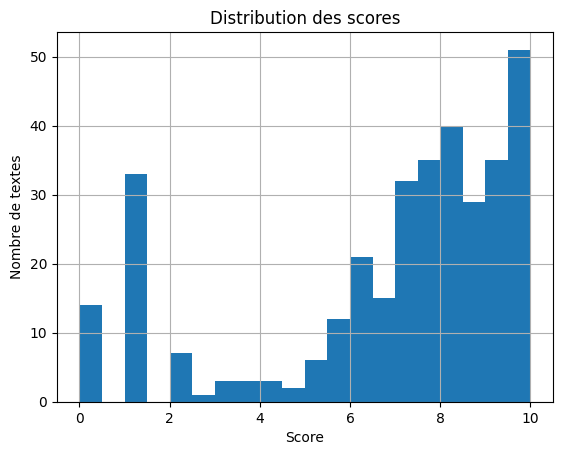

source
Wikipédia arabe                                                        262
Revue Marocaine de Publication des Recherches Scientifiques (RMPRS)     80
Name: count, dtype: int64
Score
(-1, 3]     58
(3, 6]      47
(6, 8]     122
(8, 10]    115
Name: count, dtype: int64
Doublons : 0
Nb d'articles sources : 93

=== BAS ===
0.0 | WIKI_65638 | أحمد حلمي (مواليد 18 نوفمبر 1969) هو ممثل ومقدم برامج وكاتب ومنتج أفلام مصري. كانت بدايته في التلفزيون عندما كان يُخرج برنامج لعب عيال وقد شاهدته مدير 

0.0 | WIKI_65638 | وقام بتقديم عدة برامج منها: لعب عيال (1998)، ودربكة (1998)، ومن سيربح البونبون (2004)، وشوية عيال (2011)، وحلمي أون لاين. كما شارك كعضو لجنة تحكيم في  

0.0 | WIKI_293523 | وكذا تطوير البنى التحتية؛ مع وجود لَجنة تتبُّع ومواكَبة لأهداف التنمية المستدامة «أفُق 2030» التي تَضم 19 مخططًا قطاعيًا. تتوفر البلاد على عوامل رئيسي 


=== HAUT ===
10.0 | WIKI_201605 | التعليم في المغرب هو من القطاعات الأساسية في البلاد، وتشرف عليه مؤسسات عمومية وخاصة، تشمل التعليم الأولي والتعليم الابتد

In [ ]:
import matplotlib.pyplot as plt

# 1. Histogramme des scores
df_final["Score"].hist(bins=20)
plt.xlabel("Score"); plt.ylabel("Nombre de textes"); plt.title("Distribution des scores")
plt.show()

# 2. Répartition par source et par tranche de score
print(df_final["source"].value_counts())
print(pd.cut(df_final["Score"], [-1, 3, 6, 8, 10]).value_counts().sort_index())

# 3. Doublons et textes anormaux
print("Doublons :", df_final["Text"].duplicated().sum())
print("Nb d'articles sources :", df_final["article_id"].nunique())

# 4. Lire quelques exemples bas et hauts (à regarder réellement)
for label, subset in [("BAS", df_final.nsmallest(3, "Score")),
                      ("HAUT", df_final.nlargest(3, "Score"))]:
    print(f"\n=== {label} ===")
    for _, r in subset.iterrows():
        print(r["Score"], "|", r["article_id"], "|", r["Text"][:150], "\n")

Les deux fichiers CSV sont copiés dans Google Drive pour être réutilisés dans le notebook de prétraitement.

In [ ]:
# Montage de Google Drive et copie des fichiers du dataset
from google.colab import drive
drive.mount('/content/drive')

import os
import shutil

dossier = "/content/drive/MyDrive/Projet_NLP_Education_Maroc/"
os.makedirs(dossier, exist_ok=True)

for f in ["dataset_education_maroc.csv", "dataset_education_maroc_full.csv"]:
    shutil.copy(f, dossier + f)

print("Fichiers copiés dans :", dossier)

## 9. Bilan et limites

### Résultat (dernière exécution)

- 342 passages issus de 93 articles (Wikipédia arabe : 262 passages ; RMPRS : 80 passages)
- Scores de 0 à 10 : moyenne 6,64 ; médiane 7,5
- Répartition : 58 passages entre 0 et 3, 47 entre 3 et 6, 122 entre 6 et 8, 115 entre 8 et 10
- Aucun doublon

### Limites

- Wikipédia fournit 77 % des passages. Côté RMPRS, la majorité des passages provient de l'article 484, seul article traité en texte complet.
- Le score est en partie calculé à partir de la densité de mots-clés : un modèle peut apprendre à compter ces mots plutôt qu'à juger la pertinence. Cette limite est à discuter lors de l'évaluation.
- Les passages d'un même article partagent en partie le même score manuel. L'entraînement et le test doivent être séparés par article (`article_id`) pour éviter toute fuite d'information.
- Les scores sont plus nombreux dans la partie haute de l'échelle (médiane 7,5) : les prédictions seront probablement plus précises pour les textes pertinents que pour les textes peu pertinents.
- Le corpus reste de petite taille (342 exemples).

### Suite

Le notebook suivant applique le prétraitement NLP (normalisation, tokenisation, mots vides, racinisation, lemmatisation) et prépare les données pour les modèles RNN, Bidirectional RNN, GRU et LSTM.